# Do algorithm bans pick a substitute or a ladder? FRLP screen on Qwen3-8B (demo)

**Question (claim C1).** When a prompt bans an algorithm *B* ("Do not use BFS for this task."), where does the probability mass that leaves *B* go? Two accounts compete:
- **X-specific substitution**: the ban sends mass to a *specific* substitute that depends on what was banned.
- **Generic ladder**: the mass moves along a *generic* ladder that any perturbation of the prompt also produces, for example a ban of a made-up method ("the Zorblax method"), a random edit of the prompt's hidden states, or a "write a novel algorithm" instruction.

**Setting.** `Qwen/Qwen3-8B` (thinking off) on the two path-search coding tasks from iteration 1:
- **T1 grid path**, 6 algorithms: BFS, DFS, bidirectional BFS, IDDFS, A\*, unit-weight Dijkstra (the model's default is BFS)
- **T2 weighted shortest path**, 5 algorithms: Dijkstra, Bellman-Ford/SPFA, bidirectional Dijkstra, Floyd-Warshall, Dial (default: Dijkstra)

**Instrument: forced-ratio latent probabilities (FRLP).** For each algorithm *j*, the pipeline generates programs under 10 *forced* prompts $F_j^k$ (for example "Implement {j} for this task."), labels them by behaviour, scrubs algorithm names from them, and then **teacher-forces** every program under every prompt condition *c*. An importance-sampling estimate gives the log-probability that the model writes algorithm *j* under *c*. It works even for algorithms the model almost never samples:

$$L_j(c) = \log y_j + \operatorname{logmeanexp}_{m}\big[\,\ell(p_m\mid c) - \ell_q(p_m)\big],\qquad q = \tfrac{1}{10}\textstyle\sum_k P(\cdot\mid F_j^k)$$

Here $y_j$ is the share of forced generations that really implement *j* (the yield) and $\ell_q$ is the balance-heuristic mixture proposal over the 10 forced paraphrases.

**Analysis.**
1. A **validity gate** compares FRLP with 19 distributions the model actually sampled in iteration 1.
2. The **C1 share test** splits each single-ban gain profile (ban minus a token-matched *neutral twin*) into a part along the external ladder profile *u* and an X-specific residual. It reports the noise-corrected X-specific **SHARE** with bootstrap CIs.
3. An **aim test** checks whether the residual points at the prime-and-veto profile or at the free-form association profile, against permutation nulls.

### What this notebook runs
The full pipeline (`method.py`) has two GPU stages: vLLM generation of 1,170 forced programs, and about 3.3 L4-GPU-hours of teacher-forced scoring of Qwen3-8B. Neither fits in a short Colab session. This notebook **re-runs every CPU analysis stage from the precomputed teacher-forced scores** in `mini_demo_data.json`: FRLP cells, ESS, the validity gate with 6 sensitivity variants, the C1 share test with bootstrap CIs and aim nulls, the sensitivity and secondary analyses, and the figures. It uses the original code from `src/` with minimal changes, then checks the recomputed numbers against the ones the artifact reported.

**Reported headline (artifact).**
- The gate **fails on calibration (a)**: default-mode share m = 0.83 < 0.9. It passes (b) with 0.92 nats and (c) with 16/19 hits.
- The *unscrubbed* variant passes all three criteria, so the failure is a name-scrubbing artifact.
- Pooled X-specific SHARE is 0.55 [0.25, 0.67] with neutral twins, so the branch is **UNDETERMINED**.
- The residuals are not aimed at the prime-and-veto profile (AIM −0.10, p = 0.80), and the generic profiles do not form a coherent ladder.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (logging in the original stage scripts) and rapidfuzz (token edit distance in c1.proximity)
# are NOT pre-installed on Colab -> always install
_pip('loguru==0.7.3', 'rapidfuzz==3.14.6')

# numpy, pandas, scipy, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py (orchestrator)
import argparse
import subprocess
import sys
from pathlib import Path

from loguru import logger

# src/config.py, src/frlp.py, src/analysis_misc.py, src/gate.py, src/c1.py, src/outputs.py
import collections
import io
import json
import keyword
import math
import tokenize
from dataclasses import dataclass, field
from datetime import datetime, timezone
from typing import Any, Iterable

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata, spearmanr

# notebook only: stage timings, and silence numpy's "Mean of empty slice" warnings, which the original scripts also
# emit for conditions that were never scored (the Q8 sham bans dropped at the GPU cutoff)
import time
import warnings
warnings.filterwarnings("ignore", message="Mean of empty slice", category=RuntimeWarning)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-2/experiment-7/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
T_START = time.time()
data = load_data()
md = data["metadata"]
print(md["description"])
print(f"\n{md['n_examples']} examples (forced-program sets), {md['n_score_rows']:,} teacher-forced program scores "
      f"from {md['n_scoring_units']} scoring units; model {md['model']}@{md['model_revision'][:8]}")

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
Teacher-forced scores of name-scrubbed forced programs under every scored prompt condition (Qwen/Qwen3-8B, thinking off), for the FRLP output-space screen of whether prompt-level algorithm bans pick a specific substitute or move mass along a generic ladder. One example = one (task, algorithm) forced-program set.

11 examples (forced-program sets), 38,278 teacher-forced program scores from 684 scoring units; model Qwen/Qwen3-8B@b968826d


## The demo data

`mini_demo_data.json` holds one dataset, the **teacher-forced scores**, split into **11 examples: one per (task, algorithm) forced-program set** (6 for T1, 5 for T2). Each example contains:

- `programs`: the M = 20 selected forced programs (bidirectional Dijkstra has only 11). Each program has its `half` (h1 or h2; the C1 test uses the two disjoint halves), whether it `passed` the hidden tests, the forced paraphrase that generated it, and its code before (`code_raw`) and after (`code_scrubbed`) name scrubbing.
- `scores`: one entry per scored prompt condition. Each entry holds the key `variant|cond_id` and `total`, the log-probability $\ell(p\mid c)$ (nats) of every program in the entry. `body` (fences excluded) and `cum256` (first 256 tokens) are stored only where they differ from `total`. Condition keys include:
  - `forced|bfs|plain|k3`: forced paraphrase 3, used in the mixture denominator
  - `exp1|ban:bfs|p0`: an iteration-1 gate prompt
  - `base0`: the neutral baseline prompt
  - `ban|dfs|W2`: ban template W2
  - `neutral|dfs|W2|A`: the token-matched neutral twin with noun A
  - `mention|dfs|W2`: the mention twin
  - `edit|A1001`: a matched-norm random edit of the prompt band
  - `novelty`: the "write a novel algorithm" instruction

  The variant is `primary` for name-scrubbed programs and `unscrubbed` for the raw programs.

These are exactly the rows of the artifact's 684 per-unit parquet files (`scores/cells/<task>/<uid>.parquet`). The `metadata` block carries the small JSON inputs the CPU stages read: yields $y_j$, the cut rule, the 19 gate events with the labels exp1 sampled, and the association profiles. It also carries the **reported** results, used for the comparison at the end.

In [5]:
import difflib

yl = md["yields"]["yields"]
overview = pd.DataFrame([{
    "task": ex["task"], "algorithm": ex["algorithm"], "display name": ex["display_name"],
    "forced family": ex["family"], "programs (M)": ex["n_programs"],
    "yield y_j": yl[f"{ex['task']}|{ex['algorithm']}"]["yield"],
    "programs passing tests": sum(p["passed"] for p in ex["programs"]),
    "scored conditions": len(ex["scores"]),
    "score rows": sum(len(u["prog"]) for u in ex["scores"]),
} for ex in data["examples"]])
display(overview)

# One forced DFS program after name scrubbing, and what scrubbing changed
ex = next(e for e in data["examples"] if e["task"] == "t1" and e["algorithm"] == "dfs")
p0 = ex["programs"][0]
print(f"Forced, name-scrubbed program {p0['prog_id']} (label {p0['label']}, passed tests: {p0['passed']}, "
      f"scrub mode {p0['scrub_mode']}, {p0['n_output_tokens']} tokens):\n")
print(p0["code_scrubbed"])
print("Name scrubbing (raw -> scrubbed):")
print("\n".join(difflib.unified_diff(p0["code_raw"].splitlines(), p0["code_scrubbed"].splitlines(), "raw", "scrubbed",
                                     n=0, lineterm="")))

# The kinds of prompt conditions every program of this set was scored under
first_key = {}
for u in ex["scores"]:
    k = f"{u['variant']}|{u['cond_id']}"
    first_key.setdefault("|".join(k.split("|")[:2]), k)
print(f"\n{len(ex['scores'])} scored conditions for this program set; one example key per condition family:")
print(pd.Series(first_key).to_string())
u = next(u for u in ex["scores"] if u["variant"] == "primary" and u["cond_id"] == "base0")
print("\nlog P(program | neutral baseline prompt) for the first 5 programs (nats):", [round(v, 2) for v in u["total"][:5]])

,task,algorithm,display name,forced family,programs (M),yield y_j,programs passing tests,scored conditions,score rows
0,t1,bfs,breadth-first search (BFS),plain,20,1.000000,19,271,3850
1,t1,dfs,depth-first search (DFS),plain,20,1.000000,6,271,3850
2,t1,bibfs,bidirectional BFS,plain,20,0.250000,6,271,3850
3,t1,iddfs,iterative deepening DFS (IDDFS),plain,20,1.000000,0,271,3850
4,t1,astar_gbfs,A* search,plain,20,0.355556,20,271,3850
5,t1,dijkstra,unit-weight Dijkstra,desc,20,0.766667,15,271,3850
6,t2,dijkstra,Dijkstra's algorithm,plain,20,1.000000,20,233,3330
7,t2,bf_spfa,Bellman-Ford or SPFA,plain,20,1.000000,18,233,3330
8,t2,bidijkstra,bidirectional Dijkstra,desc,11,0.116667,8,233,1858
9,t2,floyd,Floyd-Warshall,plain,20,1.000000,20,233,3330


Forced, name-scrubbed program t1|dfs|0 (label dfs, passed tests: False, scrub mode full, 264 tokens):

def solve(grid, start, goal):
    rows, cols = len(grid), len(grid[0])
    start_row, start_col = start
    goal_row, goal_col = goal

    if (start_row < 0 or start_row >= rows or start_col < 0 or start_col >= cols or
        grid[start_row][start_col] == '#' or
        grid[goal_row][goal_col] == '#'):
        return []

    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    def find_path(r, c, path):
        if (r, c) == (goal_row, goal_col):
            return path + [(r, c)]
        
        visited.add((r, c))
        for dr, dc in directions:
            nr, nc = r + dr, c + dc
            if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == '.' and (nr, nc) not in visited:
                result = find_path(nr, nc, path + [(r, c)])
                if result:
                    return result
        return None

    visited = set()
    return find_path(start_row, start_c

## Configuration

The demo has only three run-size parameters, all for resampling. **Point estimates do not depend on them**: FRLP cells, gate statistics, SHARE points, AIM values and ladder cosines are deterministic. Only the bootstrap CIs, the null quantiles and p-values, and branch labels near a threshold depend on them.

| parameter | meaning | original value |
|---|---|---|
| `DEMO_N_BOOT` | bootstrap replicates for the C1 SHARE CIs (templates, programs and random directions resampled) | 2000 (`src/config.py N_BOOT`) |
| `DEMO_N_PERM` | Monte-Carlo draws for the AIM permutation nulls | 200,000 (`src/config.py N_PERM`) |
| `DEMO_SENS_BOOT` | bootstrap replicates for each of the 12 C1 sensitivity variants | 400 (`c1.py --sens-boot`) |

The notebook runs at the **original values**. The whole CPU analysis then takes about 1–2 minutes, and because the seeds are frozen it reproduces the artifact's reported CIs and p-values exactly. Smaller values give a faster run with approximate CIs.

`DEMO_ROOT` is a local folder that mirrors the repository layout (`results/`, `logs/`, `data/`, `figures/`), so the original stage code can read and write its files unchanged.

In [6]:
# ---- Run-size parameters (point estimates do not depend on them; CIs and p-values do) ----
# Set to the artifact's ORIGINAL values: the C1 stage then takes about 45 s on 2 CPUs and reproduces every reported CI
# and p-value exactly. For a quicker look use e.g. 200 / 20_000 / 40 (about 7 s; only CIs and p-values change).
DEMO_N_BOOT = 2000       # bootstrap replicates, C1 SHARE CIs              (original: 2000    = src/config.py N_BOOT)
DEMO_N_PERM = 200_000    # Monte-Carlo draws, AIM permutation nulls         (original: 200_000 = src/config.py N_PERM)
DEMO_SENS_BOOT = 400     # bootstrap replicates per C1 sensitivity variant  (original: 400     = c1.py --sens-boot)

DEMO_ROOT = Path("frlp_demo")   # local folder mirroring the repository layout (results/, logs/, data/, figures/)

## The orchestrator: `method.py`

`method.py` is the artifact's entry point. It defines the 13 stages and runs each one as a subprocess (`uv run method.py <stage>`, or `all`). Its code is reproduced below unchanged, except that `ROOT` points at `DEMO_ROOT` and `main()` is not called.

What this notebook does with each stage:
- **Not re-run, GPU**: `generate` (vLLM, step 1) and `score` (HF teacher forcing, step 3). Their output is the score table in `mini_demo_data.json`.
- **Not re-run, need the iteration-1 suite**: `inputs`, `recheck`, `events`, `prompts` and `select` need the copied iteration-1 suite (hidden tests, sandbox, labeller). Their outputs (yields, gate events, association profiles) come with the demo data.
- **Re-run inline, CPU**: `analyse_misc` → `gate` → `analyse` → `outputs`, in the order of the artifact's `audit/final_steps.sh`.
- **Not re-run, bookkeeping**: `freeze` (profiles and hashes for the confirmation bench) and `audit` (an independent re-derivation that matched to < 1e-15).

In [7]:
"""Orchestrator: do prompt-level algorithm bans on Qwen3-8B pick a specific substitute or move mass along a generic
ladder? (FRLP output-space screen, two path-search tasks; descriptive.)

Stages (each resumes from what is on disk; GPU stages run in their own processes so vLLM and HF never coexist):
  inputs      step 0.1  copy iteration-1 inputs (paths.local.json or FRLP_EXP1/FRLP_EXP4/FRLP_DS env vars)
  recheck     step 0.2  canonical labeller on the gold set and the 22 references
  events      step 0.3  FRLP gate events from exp1 samples (hash-committed)
  prompts     step 0.4  prompts_v2.json (hash-committed before GPU work)
  generate    step 1    vLLM: forced programs (adaptive rounds) + free-form answers   [GPU]
  select      step 2    scrub / verify / select programs, association profiles
  score       step 3    HF teacher-forced scoring queue Q1..Q9 (validation, cut rule)  [GPU]
  gate        step 5    FRLP validity gate (needs Q1 + Q2)
  analyse     steps 4,6,7  cells, ESS, coverage, C1 share/aim (both references), sensitivity, secondary
  freeze      step 8    frozen profiles + code hashes for the confirmation bench
  outputs     step 9    method_out.json + figures
  audit       T6        independent re-derivation from the raw parquet files
  all         every stage in order

The proposed method is the X-specific substitution account (residual aimed at the prime-and-veto or association
profile); the baseline/rival is the generic ladder (the external profile from nonce bans, matched-norm random
prompt-band edits and a novelty instruction), with uniform and neutral/mention-twin references.
"""

ROOT = DEMO_ROOT.resolve()   # DEMO: original `Path(__file__).resolve().parent` (the repository folder)
SRC = ROOT / "src"
PY = sys.executable

STAGES = {
    "inputs": ["copy_inputs.py"],
    "recheck": ["labelling.py"],
    "events": ["gate_events.py"],
    "prompts": ["prompts_v2.py"],
    "generate": ["gen_vllm.py", "--max-num-seqs", "48"],
    "select": ["select_programs.py"],
    "score": ["frlp_score.py", "--deadline", "05:35", "--precision", "tf32"],
    "gate": ["gate.py"],
    "analyse_misc": ["analysis_misc.py"],
    "analyse": ["c1.py"],
    "freeze": ["freeze.py"],
    "outputs": ["outputs.py"],
    "audit": [str(ROOT / "audit" / "rederive.py")],
}
ORDER = ["inputs", "recheck", "events", "prompts", "generate", "select", "score", "gate", "analyse_misc", "analyse",
         "freeze", "outputs", "audit"]


def run(stage: str, extra: list[str]) -> None:
    cmd = STAGES[stage]
    script = cmd[0] if cmd[0].startswith("/") else str(SRC / cmd[0])
    full = [PY, script] + cmd[1:] + extra
    logger.info(f"stage {stage}: {' '.join(Path(c).name if c.startswith('/') else c for c in full)}")
    r = subprocess.run(full, cwd=str(SRC))
    if r.returncode != 0:
        raise SystemExit(f"stage {stage} failed with exit code {r.returncode}")


@logger.catch(reraise=True)
def main() -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("stage", choices=ORDER + ["all"])
    ap.add_argument("extra", nargs=argparse.REMAINDER, help="extra arguments passed to the stage script")
    a = ap.parse_args()
    for st in (ORDER if a.stage == "all" else [a.stage]):
        run(st, a.extra if a.stage != "all" else [])


# DEMO: in the repository this runs as `uv run method.py all` and every stage is a subprocess running src/<stage>.py.
# The GPU stages cannot run here; the CPU stages' source code is inlined in the cells below and called directly,
# in the order of audit/final_steps.sh (analyse_misc -> gate -> analyse -> outputs).
NOTEBOOK_SECTION = {"analyse_misc": "RE-RUN below (Step 4: FRLP cells, ESS)",
                    "gate": "RE-RUN below (Step 5: validity gate)",
                    "analyse": "RE-RUN below (Steps 6-7: C1 share test, sensitivity)",
                    "outputs": "RE-RUN below (Step 9: figures, method_out.json)"}
for st in ORDER:
    cmd = " ".join(Path(c).name if c.startswith("/") else c for c in STAGES[st])
    print(f"{st:13s} {cmd:50s} {NOTEBOOK_SECTION.get(st, 'not re-run (GPU / iteration-1 suite / bookkeeping)')}")

inputs        copy_inputs.py                                     not re-run (GPU / iteration-1 suite / bookkeeping)
recheck       labelling.py                                       not re-run (GPU / iteration-1 suite / bookkeeping)
events        gate_events.py                                     not re-run (GPU / iteration-1 suite / bookkeeping)
prompts       prompts_v2.py                                      not re-run (GPU / iteration-1 suite / bookkeeping)
generate      gen_vllm.py --max-num-seqs 48                      not re-run (GPU / iteration-1 suite / bookkeeping)
select        select_programs.py                                 not re-run (GPU / iteration-1 suite / bookkeeping)
score         frlp_score.py --deadline 05:35 --precision tf32    not re-run (GPU / iteration-1 suite / bookkeeping)
gate          gate.py                                            RE-RUN below (Step 5: validity gate)
analyse_misc  analysis_misc.py                                   RE-RUN below (Step 4:

## Frozen protocol: `src/config.py`

Every stage reads its names, templates, paths and thresholds from this module, so the protocol has one definition. The definitions are frozen and hash-committed before any GPU output was read. They include:
- the algorithm catalogue and display names per task
- the 5 ban/mention/neutral templates W1–W5, the nonce ban, the novelty instruction and the forced templates
- the random-edit seed families A and B
- the bootstrap seeds and counts, the ESS flag (5), and the gate thresholds for (a), (b) and (c)

Changes for the notebook: `ROOT` points at `DEMO_ROOT`. The helpers used only by the pre-registration, prompt and GPU stages are omitted. Those are the `commit`/`verify_chain` hash chain, `model_path`/`local_paths`, `add_suite_to_path`, and `display`, which is used by `prompts_v2.py` and would otherwise shadow IPython's `display`.

In [8]:
"""Frozen protocol constants and shared helpers for the FRLP ban screen (substitute vs ladder).

Every stage reads its names, templates, paths and thresholds from here, so the protocol has one definition.
"""

ROOT = DEMO_ROOT.resolve()        # DEMO: original `Path(__file__).resolve().parent.parent` (the repository folder)
SRC = ROOT / "src"
SUITE = ROOT / "suite"            # copied exp1 suite (common.py, tasks/, labeller/, gen/prompts.py, pipeline.py)
DATA_IN = ROOT / "data_in"        # copied exp1 data, exp4 directions, DS noun bank
DATA = ROOT / "data"
RESULTS = ROOT / "results"
LOGS = ROOT / "logs"
PROMPTS = ROOT / "prompts"
SCORES = ROOT / "scores"
FROZEN = ROOT / "frozen"
FIGS = ROOT / "figures"
COMMIT_LOG = ROOT / "commitments.log"
PATHS_LOCAL = ROOT / "paths.local.json"
for _d in (DATA_IN, DATA, RESULTS, LOGS, PROMPTS, SCORES, FROZEN, FIGS):
    _d.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REV = "b968826d9c46dd6066d109eabc6255188de91218"
CHAT_TAIL = "<|im_start|>assistant\n<think>\n\n</think>\n\n"
JUDGE_MODEL = "openai/gpt-4.1-mini"
JUDGE_CAP_USD = 0.5

TASKS = ("t1", "t2")
MODES: dict[str, list[str]] = {
    "t1": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
    "t2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
}
DEFAULT_MODE = {"t1": "bfs", "t2": "dijkstra"}
OTHER = "other"
# Frozen display names (direction); NOT exp1's t1 names for astar_gbfs / dijkstra.
DISPLAY: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* search",
        "dijkstra": "unit-weight Dijkstra",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
SHAMS: dict[str, dict[str, str]] = {
    "t1": {"jps": "jump point search", "idastar": "IDA* search"},
    "t2": {"johnson": "Johnson's algorithm", "yen": "Yen's k-shortest-paths algorithm"},
}
# Pre-declared content neighbours of each off-catalogue sham (step 7.3).
SHAM_NEIGHBOURS = {"idastar": ["iddfs", "astar_gbfs"], "jps": ["astar_gbfs"], "johnson": ["bf_spfa", "dijkstra"],
                   "yen": ["dijkstra"]}
NONCE = "the Zorblax method"
TWO_STEP = {"t1": ["bfs", "dfs"], "t2": ["dijkstra", "bf_spfa"]}
WS = ["W1", "W2", "W3", "W4", "W5"]
TEMPLATES: dict[str, dict[str, str]] = {
    "W1": {"ban": "Do not use {X} for this task.", "mention": "You could use {X} for this task.",
           "neutral": "Do not use {N} for this task."},
    "W2": {"ban": "Your solution must not rely on {X}.", "mention": "Your solution may rely on {X}.",
           "neutral": "Your solution must not rely on {N}."},
    "W3": {"ban": "Avoid {X} entirely.", "mention": "Consider {X} first.", "neutral": "Avoid {N} entirely."},
    "W4": {"ban": "{X} is not allowed here.", "mention": "{X} is allowed here.", "neutral": "{N} is not allowed here."},
    "W5": {"ban": "Write a correct solution that does not use {X}.",
           "mention": "Write a correct solution that may use {X}.",
           "neutral": "Write a correct solution that does not use {N}."},
}
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
FORCED_TEMPLATES = [
    "Implement {j} for this task.", "Use {j} to solve this task.", "Solve this task with {j}.",
    "Your solution should use {j}.", "Write an implementation based on {j}.", "Solve this task by implementing {j}.",
    "Please implement {j} for this task.", "The solution must use {j}.", "Write a solution that uses {j}.",
    "Apply {j} to this task.",
]
FREE_TEMPLATE = "What is the standard alternative to {X} for this task? Answer with the name of one algorithm only."
FILLERS = [" .", " -", " ok"]
EDIT_LAYERS = list(range(12, 25))      # decoder layers 12..24 (outputs = hidden_states[l+1])
RAND_SEEDS = {"A": [1001, 1002, 1003], "B": [2001, 2002, 2003]}
VARIANT_II_LAYER = 18
VARIANT_II_COEF = 0.25
N_FORCED_TARGET = 30
MIN_MEASURABLE = 10
SEED_SELECT = 7
SEED_HALVES = 11
SEED_BOOT = 13
N_BOOT = 2000
N_PERM = 200_000
ESS_FLAG = 5.0
GATE_A_S_RANGE = (0.3, 3.0)
GATE_A_M_MIN = 0.9
GATE_B_MIN = 0.3
GATE_C_MIN = 0.8
CLEAR_MODE_MARGIN = 0.15
LADDER_COS_MIN = 0.5
TRUNC_TOKENS = [64, 128, 256, 384]

# Name lexicon for scrubbing (step 2.2), case-insensitive, word/underscore boundaries.
SCRUB_PHRASES = [
    r"breadth[- ]first", r"depth[- ]first", r"bi[- ]?directional", r"iterative[- ]deepening", r"greedy best[- ]first",
    r"best[- ]first", r"bellman[- ]?ford", r"shortest path faster", r"uniform[- ]cost", r"jump point", r"A\*",
    r"A-star", r"IDA\*", r"BFS", r"DFS", r"IDDFS", r"astar", r"a_star", r"GBFS", r"Dijkstra'?s?", r"SPFA",
    r"Floyd", r"Warshall", r"Dial'?s?", r"UCS", r"JPS", r"Johnson'?s?", r"Yen'?s?",
]
SCRUB_STEMS = ["bfs", "dfs", "iddfs", "dijkstra", "bellman", "spfa", "floyd", "warshall", "astar", "a_star", "dial",
               "bidir", "gbfs", "jps", "johnson", "yen", "bibfs", "bidijkstra", "ucs", "idastar"]


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    rows: list[dict[str, Any]] = []
    if not p.exists():
        return rows
    with p.open() as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed jsonl line in {p.name}")
    return rows


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with tmp.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(r, ensure_ascii=False, default=_json_default) + "\n")
    tmp.replace(p)


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        v = float(o)
        return None if math.isnan(v) else v
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, ensure_ascii=False, default=_json_default))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def logsumexp(a, axis=None):
    import numpy as np

    a = np.asarray(a, dtype=np.float64)
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return np.squeeze(out, axis=axis) if axis is not None else float(out.squeeze())


print("ban templates:", {w: TEMPLATES[w]["ban"] for w in WS})

ban templates: {'W1': 'Do not use {X} for this task.', 'W2': 'Your solution must not rely on {X}.', 'W3': 'Avoid {X} entirely.', 'W4': '{X} is not allowed here.', 'W5': 'Write a correct solution that does not use {X}.'}


## Unpack the demo inputs into the repository layout

The original CPU stages read these small inputs from files inside the repository:

| file | produced by | content |
|---|---|---|
| `results/yields.json` | step 2 (`select`) | yield $y_j$ and measurability of each algorithm |
| `logs/throughput.json` | step 3 (`score`) | the cut rule: M = 20 programs per algorithm, 3 gate paraphrases |
| `results/gate_events.json` | step 0.3 (`events`) | the 19 exp1 events and the labels exp1 sampled under each paraphrase |
| `results/association.json` | step 2 (`select`) | free-form association profiles ("What is the standard alternative to X?") |
| `data/forced_selected.jsonl` | step 2 (`select`) | the selected forced programs: half, passed, paraphrase, rank |

The cell below writes them from `data` into `DEMO_ROOT`, so the stage code runs unchanged. Only one input is handled differently: the 684 per-unit parquet score files are replaced by `load_scores()`, which reads the same rows from `data`.

In [9]:
# The same JSON inputs the original stages read from disk, written from mini_demo_data.json into DEMO_ROOT
write_json(RESULTS / "yields.json", md["yields"])            # step 2: yields y_j, measurability
write_json(LOGS / "throughput.json", md["throughput"])        # step 3: cut rule (M programs, gate paraphrases)
write_json(RESULTS / "gate_events.json", md["gate_events"])   # step 0.3: 19 exp1 events with sampled labels
write_json(RESULTS / "association.json", md["association"])   # step 2: free-form association profiles
write_jsonl(DATA / "forced_selected.jsonl", [p for ex in data["examples"] for p in ex["programs"]])  # step 2

for p in sorted(ROOT.rglob("*.json*")):
    print(f"{str(p.relative_to(ROOT)):30s} {p.stat().st_size / 1e3:8.1f} kB")
print(f"cut rule: M = {md['throughput']['M']} programs per algorithm, "
      f"{md['throughput']['gate_paraphrases']} gate paraphrases")

data/forced_selected.jsonl        558.3 kB
logs/throughput.json                0.4 kB
results/association.json            2.3 kB
results/gate_events.json           73.9 kB
results/yields.json                 5.5 kB
cut rule: M = 20 programs per algorithm, 3 gate paraphrases


## Step 4: forced-ratio latent probabilities (`src/frlp.py`)

For task *t*, condition *c*, algorithm *j* and a program set *P* of forced *j*-programs, each program has an importance log-weight $lw_m = \ell(p_m\mid c) - \ell_q(p_m)$. From these:
- $L_j(c) = \log y_j + \operatorname{logsumexp}_m(lw_m) - \log|P|$, the yield-corrected estimate of $\log P(j\mid c)$
- $L_{raw} = L_j(c) - \log y_j$, the literal formula
- $\mathrm{ESS} = \exp\big(2\,\operatorname{lse}(lw) - \operatorname{lse}(2\,lw)\big)$, the effective sample size

`TaskData` holds, per task:
- the program table
- the pivoted score matrices `L[col]`, with rows (variant|condition) and columns programs
- the denominators `lq`: the **mixture** over the 10 forced paraphrases (primary), the **single** generating paraphrase, and their **raw** (unscrubbed) counterparts

`VARIANTS` lists the 7 FRLP variants used by the gate and the sensitivity analyses. Each variant picks a score column, a denominator, a program filter, and scrubbed or unscrubbed programs.

**Change for the notebook:** `load_scores()` reads the rows from `data` instead of the 684 parquet files. Everything else is the original code. `coverage()` is not included because it needs exp1's natural programs, which are not in the demo data.

In [10]:
UNITS_DONE = SCORES / "units_done.jsonl"
M_SCORED = 30
SCORE_COLS = ("total", "body", "cum256")
VARIANTS = {  # name -> (score column, denominator kind, program filter, scrubbed?)
    "primary": ("total", "mixture", "all", "primary"),
    "code_body_only": ("body", "mixture", "all", "primary"),
    "correct_only": ("total", "mixture", "passed", "primary"),
    "single_proposal": ("total", "single", "all", "primary"),
    "truncated_256": ("cum256", "mixture", "all", "primary"),
    "unscrubbed": ("total", "mixture_raw", "all", "unscrubbed"),
    "unscrubbed_body_single": ("body", "single_raw", "all", "unscrubbed"),
}


def load_scores() -> pd.DataFrame:
    """DEMO version. The original reads scores/units_done.jsonl and one parquet file per scoring unit
    (scores/cells/<task>/<uid>.parquet, one row per program) and concatenates them. mini_demo_data.json holds the same
    rows grouped by (task, algorithm); this rebuilds the identical long table (one row per unit x program)."""
    cols = collections.defaultdict(list)
    for ex in data["examples"]:
        pids = [p["prog_id"] for p in ex["programs"]]
        for u in ex["scores"]:
            n = len(u["prog"])
            cols["prog_id"] += [pids[i] for i in u["prog"]]
            for c in SCORE_COLS:  # body / cum256 are stored as null when identical to total
                cols[c] += u["total"] if u.get(c) is None else u[c]
            cols["task"] += [ex["task"]] * n
            for k in ("queue", "cond_id", "progset", "variant"):
                cols[k] += [u[k]] * n
            cols["direction"] += [u.get("direction")] * n
    return pd.DataFrame(cols)


@dataclass
class TaskData:
    task: str
    progs: pd.DataFrame                       # index prog_id: j, half, passed, paraphrase_id, family
    yields: dict[str, float]
    yields_pass: dict[str, float]
    measurable: list[str]
    L: dict[str, pd.DataFrame] = field(default_factory=dict)        # column -> (variant|cond) x prog_id
    lq: dict[str, pd.Series] = field(default_factory=dict)          # denominator kind|column -> prog_id

    def key(self, cond: str, variant: str = "primary") -> str:
        return f"{variant}|{cond}"

    def lw(self, cond: str, vname: str = "primary") -> pd.Series:
        col, den, _filt, scr = VARIANTS[vname]
        k = self.key(cond, "unscrubbed" if scr == "unscrubbed" else self._variant_of(cond))
        if k not in self.L[col].index:
            raise KeyError(k)
        return self.L[col].loc[k] - self.lq[f"{den}|{col}"]

    @staticmethod
    def _variant_of(cond: str) -> str:
        if cond.startswith("edit2|"):
            return "edit2"
        if cond.startswith("edit|"):
            return "edit"
        return "primary"

    def has(self, cond: str, vname: str = "primary") -> bool:
        col, _d, _f, scr = VARIANTS[vname]
        k = self.key(cond, "unscrubbed" if scr == "unscrubbed" else self._variant_of(cond))
        return k in self.L[col].index

    def pids(self, j: str, half: str = "all", vname: str = "primary") -> list[str]:
        _c, _d, filt, _s = VARIANTS[vname]
        p = self.progs[self.progs["j"] == j]
        if half in ("h1", "h2"):
            p = p[p["half"] == half]
        if filt == "passed":
            p = p[p["passed"]]
        return list(p.index)

    def cell(self, cond: str, j: str, half: str = "all", vname: str = "primary") -> dict[str, Any]:
        """Point estimate of L_j(cond) on the given half; NaN if not scored."""
        pids = self.pids(j, half, vname)
        try:
            lw = self.lw(cond, vname).reindex(pids).to_numpy(dtype=float)
        except KeyError:
            return {"L": math.nan, "L_raw": math.nan, "ess": math.nan, "n": 0}
        lw = lw[np.isfinite(lw)]
        if len(lw) == 0:
            return {"L": math.nan, "L_raw": math.nan, "ess": math.nan, "n": 0}
        lse = logsumexp(lw)
        L_raw = lse - math.log(len(lw))
        y = self.yields_pass[j] if VARIANTS[vname][2] == "passed" else self.yields[j]
        ess = math.exp(2 * lse - logsumexp(2 * lw))
        return {"L": L_raw + math.log(max(y, 1e-12)), "L_raw": L_raw, "ess": ess, "n": int(len(lw))}


def _m_scored() -> int:
    p = LOGS / "throughput.json"   # (original: `from config import LOGS` inside the function)
    return int(read_json(p)["M"]) if p.exists() else 30


def build_task_data(scores: pd.DataFrame | None = None) -> dict[str, TaskData]:
    M_SCORED = _m_scored()
    globals()["M_SCORED"] = M_SCORED
    if scores is None:
        scores = load_scores()
    sel = pd.DataFrame(read_jsonl(DATA / "forced_selected.jsonl")).set_index("prog_id")
    yl = read_json(RESULTS / "yields.json")["yields"]
    out = {}
    for t in TASKS:
        df = scores[scores["task"] == t]
        progs = sel[sel["task"] == t][["j", "half", "passed", "paraphrase_id", "family", "rank", "m_j"]].copy()
        progs = progs[progs["rank"] < np.minimum(progs["m_j"], M_SCORED)]
        meas = [j for j in MODES[t] if yl.get(f"{t}|{j}", {}).get("measurable") and (progs["j"] == j).any()]
        y = {j: yl[f"{t}|{j}"]["yield"] for j in meas}
        yp = {j: yl[f"{t}|{j}"]["passed_labelled_" + yl[f"{t}|{j}"]["family"]]
              / max(1, yl[f"{t}|{j}"]["attempts_" + yl[f"{t}|{j}"]["family"]]) for j in meas}
        td = TaskData(task=t, progs=progs, yields=y, yields_pass=yp, measurable=meas)
        if df.empty:
            out[t] = td
            continue
        df = df.assign(key=df["variant"] + "|" + df["cond_id"])
        for col in SCORE_COLS:
            td.L[col] = df.pivot_table(index="key", columns="prog_id", values=col, aggfunc="first")
        # denominators: balance-heuristic mixture over the family's 10 paraphrases; single = generating paraphrase
        for col in SCORE_COLS:
            mix, single = {}, {}
            for pid, r in progs.iterrows():
                keys = [f"primary|forced|{r['j']}|{r['family']}|k{k}" for k in range(10)]
                vals = [td.L[col].at[k, pid] if (k in td.L[col].index and pid in td.L[col].columns) else np.nan
                        for k in keys]
                vals = np.array(vals, dtype=float)
                if np.isfinite(vals).all():
                    mix[pid] = logsumexp(vals) - math.log(10)
                kg = int(r["paraphrase_id"])
                single[pid] = vals[kg] if np.isfinite(vals[kg]) else np.nan
            td.lq[f"mixture|{col}"] = pd.Series(mix, dtype=float)
            td.lq[f"single|{col}"] = pd.Series(single, dtype=float)
            raw, rawmix = {}, {}
            for pid, r in progs.iterrows():
                k = f"unscrubbed|forced|{r['j']}|{r['family']}|k{int(r['paraphrase_id'])}"
                if k in td.L[col].index and pid in td.L[col].columns:
                    raw[pid] = td.L[col].at[k, pid]
                keys = [f"unscrubbed|forced|{r['j']}|{r['family']}|k{kk}" for kk in range(10)]
                vals = np.array([td.L[col].at[k2, pid] if (k2 in td.L[col].index and pid in td.L[col].columns)
                                 else np.nan for k2 in keys], dtype=float)
                if np.isfinite(vals).all():
                    rawmix[pid] = logsumexp(vals) - math.log(10)
            td.lq[f"single_raw|{col}"] = pd.Series(raw, dtype=float)
            td.lq[f"mixture_raw|{col}"] = pd.Series(rawmix, dtype=float)
        out[t] = td
    return out


def mixture_identity(tds: dict[str, TaskData]) -> dict[str, Any]:
    """Validation (v): logmeanexp_k l(p|F_j^k) - l_q(p) == 0 (recomputed independently with numpy)."""
    worst = 0.0
    n = 0
    for t, td in tds.items():
        if "total" not in td.L:
            continue
        for pid, r in td.progs.iterrows():
            keys = [f"primary|forced|{r['j']}|{r['family']}|k{k}" for k in range(10)]
            if not all(k in td.L["total"].index for k in keys) or pid not in td.lq["mixture|total"].index:
                continue
            v = td.L["total"].loc[keys, pid].to_numpy(dtype=np.float64)
            lme = np.log(np.mean(np.exp(v - v.max()))) + v.max()
            worst = max(worst, abs(lme - td.lq["mixture|total"][pid]))
            n += 1
    return {"n_programs": n, "max_abs_diff": worst, "pass": bool(n > 0 and worst < 1e-6)}


def write_cells(tds: dict[str, TaskData], path=RESULTS / "frlp_cells.jsonl") -> int:
    rows = []
    for t, td in tds.items():
        if "total" not in td.L:
            continue
        conds = sorted({k.split("|", 1)[1] for k in td.L["total"].index})
        for cond in conds:
            for vname in VARIANTS:
                if not td.has(cond, vname):
                    continue
                for j in td.measurable:
                    for half in ("all", "h1", "h2"):
                        c = td.cell(cond, j, half, vname)
                        if c["n"] == 0:
                            continue
                        parts = cond.split("|")
                        rows.append({"task": t, "model": MODEL_ID, "condition": cond,
                                     "template": next((p for p in parts if p.startswith("W")), None),
                                     "algorithm": j, "L": c["L"], "L_raw": c["L_raw"], "ess": c["ess"],
                                     "n_programs": c["n"], "half": half, "variant": vname})
    write_jsonl(path, rows)
    logger.info(f"wrote {len(rows)} FRLP cells")
    return len(rows)

### Vectorised cells for the bootstrap: `CellArrays`

The C1 bootstrap resamples programs within each algorithm-half, so every replicate needs the FRLP cells recomputed. `CellArrays` precomputes the importance weights $e^{lw - \text{shift}}$ for every (condition, program) pair. A replicate is then just a matrix–vector product with a vector of per-program multiplicity weights *W*; W = 1 gives the point estimate.

It also builds the **virtual neutral twin** `neutral|X|W|AB`, which uses noun A on half h1 and noun B on half h2. That keeps the noun and the program half disjoint.

In [11]:
# ------------------------------------------------------------------------------------------------ fast arrays
class CellArrays:
    """Vectorised cells for the bootstrap: for each condition row c and algorithm j, L over h1, h2 and all,
    recomputed from per-program multiplicity weights W (W = 1 is the point estimate)."""

    def __init__(self, td: TaskData, conds: list[str], vname: str = "primary",
                 virtual: dict[str, tuple[str, str]] | None = None) -> None:
        self.td, self.vname = td, vname
        self.conds = list(conds) + list((virtual or {}).keys())
        self.cidx = {c: i for i, c in enumerate(self.conds)}
        self.js = [j for j in td.measurable if td.pids(j, "all", vname)]  # e.g. correct_only drops j with no passes
        pids = [p for j in self.js for p in td.pids(j, "all", vname)]
        self.pids = pids
        self.pj = np.array([self.js.index(td.progs.at[p, "j"]) for p in pids])
        self.ph = np.array([0 if td.progs.at[p, "half"] == "h1" else 1 for p in pids])
        lw = np.full((len(self.conds), len(pids)), np.nan)
        for i, c in enumerate(conds):
            if td.has(c, vname):
                lw[i] = td.lw(c, vname).reindex(pids).to_numpy(dtype=float)
        for name, (ca, cb) in (virtual or {}).items():
            i = self.cidx[name]
            a = td.lw(ca, vname).reindex(pids).to_numpy(dtype=float) if td.has(ca, vname) else np.full(len(pids), np.nan)
            b = td.lw(cb, vname).reindex(pids).to_numpy(dtype=float) if td.has(cb, vname) else np.full(len(pids), np.nan)
            lw[i] = np.where(self.ph == 0, a, b)
        self.lw = lw
        self.valid = np.isfinite(lw)
        shift = np.zeros((len(self.conds), len(self.js)))
        for k in range(len(self.js)):
            m = self.pj == k
            if not m.any():
                continue
            sub = np.where(self.valid[:, m], lw[:, m], -np.inf)
            mx = sub.max(axis=1)
            shift[:, k] = np.where(np.isfinite(mx), mx, 0.0)
        self.shift = shift
        self.E = np.where(self.valid, np.exp(np.where(self.valid, lw, 0.0) - shift[:, self.pj]), 0.0)
        self.E2 = self.E ** 2
        y = td.yields_pass if VARIANTS[vname][2] == "passed" else td.yields
        self.logy = np.log(np.maximum(np.array([y[j] for j in self.js]), 1e-12))

    def cells(self, W: np.ndarray | None = None, with_ess: bool = False):
        """Returns L[h] arrays (n_cond x K) for h in ('h1','h2','all'); NaN where not scored."""
        if W is None:
            W = np.ones(len(self.pids))
        out, ess = {}, {}
        for hname, hmask in (("h1", self.ph == 0), ("h2", self.ph == 1), ("all", np.ones(len(self.pids), bool))):
            L = np.full((len(self.conds), len(self.js)), np.nan)
            Es = np.full((len(self.conds), len(self.js)), np.nan)
            for k in range(len(self.js)):
                m = (self.pj == k) & hmask
                if not m.any():
                    continue
                Wm = W[m]
                Vm = self.valid[:, m]
                n = Vm.astype(float) @ Wm
                s = self.E[:, m] @ Wm
                ok = (n > 0) & (s > 0)
                L[ok, k] = self.logy[k] + self.shift[ok, k] + np.log(s[ok]) - np.log(n[ok])
                if with_ess:
                    s2 = self.E2[:, m] @ Wm
                    Es[ok, k] = s[ok] ** 2 / s2[ok]
            out[hname] = L
            ess[hname] = Es
        return (out, ess) if with_ess else out

    def boot_weights(self, rng: np.random.Generator) -> np.ndarray:
        W = np.zeros(len(self.pids))
        for k in range(len(self.js)):
            for h in (0, 1):
                idx = np.where((self.pj == k) & (self.ph == h))[0]
                if len(idx):
                    W[idx] = rng.multinomial(len(idx), np.full(len(idx), 1 / len(idx)))
        return W

### Run stage `analyse_misc` (`src/analysis_misc.py`)

This stage does three things:
1. Builds the task data.
2. Checks the **mixture identity**: the stored denominator equals $\operatorname{logmeanexp}_k \ell(p\mid F_j^k)$, recomputed independently.
3. Writes **every FRLP cell** (all conditions × 7 variants × measurable algorithms × {all, h1, h2}) to `results/frlp_cells.jsonl`, and summarises the **ESS per condition family**.

Two parts of the original stage are not run: `coverage()`, which needs exp1's natural programs, and `bookkeeping()` (timings, cost and protocol files).

In [12]:
def ess_table() -> dict[str, Any]:
    rows = read_jsonl(RESULTS / "frlp_cells.jsonl")
    fam = collections.defaultdict(list)
    for r in rows:
        if r["variant"] != "primary" or r["half"] == "all" or r["ess"] is None:
            continue
        kind = r["condition"].split("|")[0]
        if kind == "exp1":
            kind = "exp1_gate"
        fam[(r["task"], kind)].append(r["ess"])
    return {f"{t}|{k}": {"n_cells": len(v), "median_ess": float(np.median(v)), "frac_below_5": float(np.mean(
        np.array(v) < ESS_FLAG)), "p10": float(np.quantile(v, 0.1)), "p90": float(np.quantile(v, 0.9))}
            for (t, k), v in sorted(fam.items())}


@logger.catch(reraise=True)
def main() -> None:
    setup_logging("analysis_misc")
    tds = build_task_data()
    mi = mixture_identity(tds)
    write_json(RESULTS / "mixture_identity.json", mi)
    logger.info(f"mixture identity: {mi}")
    n = write_cells(tds)
    write_json(RESULTS / "ess_table.json", ess_table())
    # write_json(RESULTS / "coverage.json", coverage())  # DEMO: skipped (needs exp1's natural programs)
    # bookkeeping()                                      # DEMO: skipped (timings / cost / deviations / protocol files)
    logger.info(f"analysis_misc done ({n} cells) at {utc_now()}")


t0 = time.time()
main()   # == `uv run method.py analyse_misc`
print(f"stage analyse_misc: {time.time() - t0:.1f} s")

11:39:23|INFO   |mixture identity: {'n_programs': 211, 'max_abs_diff': np.float64(2.842170943040401e-14), 'pass': True}


11:39:41|INFO   |wrote 28953 FRLP cells


11:39:41|INFO   |analysis_misc done (28953 cells) at 2026-10-25T11:39:41.772233Z


stage analyse_misc: 18.8 s


In [13]:
# What the FRLP cells say: implied distribution over algorithms, p_j = exp(L_j) / sum_k exp(L_k), under the neutral
# baseline prompt, a ban of the model's default algorithm and a mention of it (template W1, all programs)
cells = pd.DataFrame(read_jsonl(RESULTS / "frlp_cells.jsonl"))
print(f"{len(cells):,} FRLP cells written; mixture identity: {read_json(RESULTS / 'mixture_identity.json')}")
for t in TASKS:
    B = DEFAULT_MODE[t]
    conds = {"baseline (base0)": "base0", f"ban {B} (W1)": f"ban|{B}|W1", f"mention {B} (W1)": f"mention|{B}|W1",
             "nonce ban (W1)": "ban|nonce|W1", "novelty instruction": "novelty"}
    sub = cells[(cells.task == t) & (cells.variant == "primary") & (cells.half == "all")]
    tab = {}
    for name, c in conds.items():
        L = sub[sub.condition == c].set_index("algorithm")["L"].reindex(MODES[t])
        tab[name] = np.exp(L - L.max()) / np.exp(L - L.max()).sum()
    print(f"\n{t}: FRLP-implied share of each algorithm (default mode: {B})")
    display(pd.DataFrame(tab).round(3))

print("ESS per condition family (primary variant, half-cells):")
display(pd.DataFrame(read_json(RESULTS / "ess_table.json")).T.round(2))

28,953 FRLP cells written; mixture identity: {'n_programs': 211, 'max_abs_diff': 2.842170943040401e-14, 'pass': True}

t1: FRLP-implied share of each algorithm (default mode: bfs)


,baseline (base0),ban bfs (W1),mention bfs (W1),nonce ban (W1),novelty instruction
algorithm,,,,,
bfs,0.536,0.0,1.0,0.001,0.0
dfs,0.464,1.0,0.0,0.999,1.0
bibfs,0.000,0.0,0.0,0.000,0.0
iddfs,0.000,0.0,0.0,0.000,0.0
astar_gbfs,0.000,0.0,0.0,0.000,0.0
dijkstra,0.000,0.0,0.0,0.000,0.0



t2: FRLP-implied share of each algorithm (default mode: dijkstra)


,baseline (base0),ban dijkstra (W1),mention dijkstra (W1),nonce ban (W1),novelty instruction
algorithm,,,,,
dijkstra,1.0,0.93,1.0,1.0,0.928
bf_spfa,0.0,0.07,0.0,0.0,0.072
bidijkstra,0.0,0.00,0.0,0.0,0.000
floyd,0.0,0.00,0.0,0.0,0.000
dial,0.0,0.00,0.0,0.0,0.000


ESS per condition family (primary variant, half-cells):


,n_cells,median_ess,frac_below_5,p10,p90
t1|ban,516.0,1.13,0.99,1.00,2.55
t1|base0,12.0,1.07,1.00,1.00,3.68
t1|edit,72.0,1.19,0.99,1.00,2.66
t1|exp1_gate,228.0,1.21,0.98,1.00,2.81
t1|forced,120.0,5.61,0.43,2.69,7.43
t1|mention,360.0,1.20,0.96,1.00,3.38
t1|neutral,516.0,1.08,0.98,1.00,3.83
t1|novelty,12.0,1.10,1.00,1.00,1.59
t2|ban,350.0,1.17,0.97,1.00,2.04
t2|base0,10.0,1.40,1.00,1.00,2.17


## Step 5: FRLP validity gate (`src/gate.py`)

Before C1 is interpreted, FRLP is checked against the **19 events whose label distributions exp1 actually sampled**: the baseline, modal bans, mentions, list-all, and absent bans. The definitions were frozen in `commitments.log`.

- **(a) Calibration** on the exp1 baseline paraphrases: $S = \sum_j e^{L_j}$ over measurable *j* and $m = e^{L_{default}}/S$. Passes if mean S ∈ [0.3, 3] and mean m ≥ 0.9.
- **(b) Discrimination**: per event *e* and paraphrase *k*, $q_{ek}(j) \propto e^{L_j(e,k)}$ over the allowed labels (half-1 programs). Smoothed: $q' = 0.93\,q + 0.05\,\text{uniform} + 0.02\,\text{other}$. The score $d$ is the mean over the paraphrase's sampled labels of $\log q'(\text{label}) - \log u(\text{label})$. Passes if the mean $d_e$ ≥ 0.3 nats.
- **(c) Argmax**: $\arg\max_j \bar q_e(j)$ equals the realised mode in ≥ 80% of clear-mode events.

`main()` runs the primary gate, re-runs it for every sensitivity variant (reported, not adopted), and computes the descriptive two-step succession check.

In [14]:
def implied(td: TaskData, cond: str, allowed: list[str], half: str, vname: str) -> tuple[dict[str, float], dict]:
    Ls, ess = {}, {}
    for j in allowed:
        if j in td.measurable:
            c = td.cell(cond, j, half, vname)
            if c["n"] > 0 and np.isfinite(c["L"]):
                Ls[j] = c["L"]
                ess[j] = c["ess"]
    if not Ls:
        return {}, ess
    mx = max(Ls.values())
    z = sum(math.exp(v - mx) for v in Ls.values())
    return {j: (math.exp(Ls[j] - mx) / z if j in Ls else 0.0) for j in allowed}, ess


def gate(tds: dict[str, TaskData], vname: str = "primary", max_para: int = 5) -> dict[str, Any]:
    ev_file = read_json(RESULTS / "gate_events.json")
    res: dict[str, Any] = {"variant": vname, "events": [], "gate_a": {}}
    # (a)
    S_all, m_all = [], []
    for t in TASKS:
        td = tds[t]
        base = next(e for e in ev_file["events"] if e["event_id"] == f"{t}|baseline")
        rows = []
        for p in base["paraphrases"][:max_para]:
            cond = f"exp1|baseline|p{p['paraphrase_id']}"
            Ls = {j: td.cell(cond, j, "all", vname)["L"] for j in td.measurable}
            Ls = {j: v for j, v in Ls.items() if np.isfinite(v)}
            if not Ls:
                continue
            S = sum(math.exp(v) for v in Ls.values())
            m = math.exp(Ls.get(DEFAULT_MODE[t], -math.inf)) / S if S > 0 else math.nan
            rows.append({"paraphrase_id": p["paraphrase_id"], "S": S, "m_default": m,
                         "L": Ls})
            S_all.append(S)
            m_all.append(m)
        res["gate_a"][t] = rows
    mS = float(np.mean(S_all)) if S_all else math.nan
    mm = float(np.mean(m_all)) if m_all else math.nan
    res["a"] = {"mean_S": mS, "mean_m_default": mm,
                "pass": bool(GATE_A_S_RANGE[0] <= mS <= GATE_A_S_RANGE[1] and mm >= GATE_A_M_MIN)}
    # (b) and (c)
    d_events, hits, n_clear, low_ess, n_cells = [], 0, 0, 0, 0
    pooled_impl, pooled_real = [], []
    for e in ev_file["events"]:
        t = e["task"]
        td = tds[t]
        allowed = [j for j in MODES[t] if j not in e["banned"]]
        per_para, qs = [], []
        for p in e["paraphrases"][:max_para]:
            cond = f"exp1|{e['condition']}|p{p['paraphrase_id']}"
            q, ess = implied(td, cond, allowed, "h1", vname)
            for v in ess.values():
                n_cells += 1
                low_ess += int(v < ESS_FLAG)
            if not q:
                continue
            qs.append(q)
            ua = 0.98 / len(allowed)
            labs = [lbl if lbl in MODES[t] else OTHER for lbl in p["labels"]]
            excluded = sum(lbl in e["banned"] for lbl in labs)
            ds = []
            for lbl in labs:
                if lbl in e["banned"]:
                    continue
                if lbl == OTHER:
                    ds.append(0.0)
                else:
                    qp = 0.93 * q.get(lbl, 0.0) + 0.05 / len(allowed)
                    ds.append(math.log(qp) - math.log(ua))
            per_para.append({"paraphrase_id": p["paraphrase_id"], "d": float(np.mean(ds)) if ds else math.nan,
                             "n_scored": len(ds), "n_banned_excluded": excluded, "q": q,
                             "ess": ess})
        if not qs:
            continue
        qbar = {j: float(np.mean([q[j] for q in qs])) for j in allowed}
        d_e = float(np.nanmean([pp["d"] for pp in per_para]))
        arg = max(qbar, key=qbar.get)
        real = e["distribution_allowed"]
        n_real = sum(v for k, v in real.items() if k != OTHER) or 1
        for j in allowed:
            pooled_impl.append(qbar[j])
            pooled_real.append(real.get(j, 0) / n_real)
        hit = arg == e["realised_mode"]
        if e["clear_mode"]:
            n_clear += 1
            hits += int(hit)
        d_events.append(d_e)
        res["events"].append({"event_id": e["event_id"], "d_e": d_e, "implied_mean": qbar, "argmax": arg,
                              "realised_mode": e["realised_mode"], "realised_allowed": real, "hit": hit,
                              "clear_mode": e["clear_mode"], "paraphrases": per_para})
    mean_d = float(np.mean(d_events)) if d_events else math.nan
    res["b"] = {"mean_d_e": mean_d, "n_events": len(d_events), "pass": bool(mean_d >= GATE_B_MIN)}
    res["c"] = {"hits": hits, "n_clear": n_clear, "rate": hits / max(1, n_clear),
                "pass": bool(n_clear > 0 and hits / n_clear >= GATE_C_MIN)}
    res["pass"] = bool(res["a"]["pass"] and res["b"]["pass"] and res["c"]["pass"])
    rho = spearmanr(pooled_impl, pooled_real).correlation if len(pooled_impl) > 2 else math.nan
    res["pooled_spearman_implied_vs_realised"] = float(rho) if rho is not None else math.nan
    res["ess_cells"] = {"n": n_cells, "n_below_5": low_ess, "frac_below_5": low_ess / max(1, n_cells),
                        "flag_more_than_half_low": bool(low_ess > n_cells / 2)}
    if not res["pass"]:
        res["failure_kind"] = [k for k in ("a", "b", "c") if not res[k]["pass"]]
    return res


def succession_descriptive(tds: dict[str, TaskData]) -> dict[str, Any]:
    """Step 7.2 part: FRLP-implied landing under exp1's own step-2 prompts vs exp1's sampled step-2 labels."""
    ev_file = read_json(RESULTS / "gate_events.json")
    out = {}
    for e in ev_file["succession_step2_descriptive"]:
        t = e["task"]
        td = tds[t]
        allowed = [j for j in MODES[t] if j not in e["banned"]]
        qs, banned_mass = [], []
        for p in e["paraphrases"]:
            cond = f"exp1|succession:2|p{p['paraphrase_id']}"
            q, _ = implied(td, cond, allowed, "h1", "primary")
            if q:
                qs.append(q)
            Ls = {j: td.cell(cond, j, "h1", "primary")["L"] for j in td.measurable}
            Ls = {j: v for j, v in Ls.items() if np.isfinite(v)}
            if Ls:
                tot = sum(math.exp(v) for v in Ls.values())
                banned_mass.append(sum(math.exp(Ls[j]) for j in e["banned"] if j in Ls) / tot)
        out[e["event_id"]] = {
            "implied_landing": {j: float(np.mean([q[j] for q in qs])) for j in allowed} if qs else None,
            "implied_banned_mass": float(np.mean(banned_mass)) if banned_mass else None,
            "exp1_realised": e["distribution_attempted"], "exp1_banned_share":
                e["n_banned_label_samples"] / max(1, e["n_samples"])}
    return out


@logger.catch(reraise=True)
def main() -> None:
    setup_logging("gate")
    tds = build_task_data()
    tp = read_json(RESULTS.parent / "logs" / "throughput.json")
    max_para = int(tp.get("gate_paraphrases", 5))
    out = {"utc": utc_now(), "primary": gate(tds, "primary", max_para)}
    out["sensitivity"] = {}
    for v in VARIANTS:
        if v == "primary":
            continue
        g = gate(tds, v, max_para)
        out["sensitivity"][v] = {k: g[k] for k in ("a", "b", "c", "pass", "pooled_spearman_implied_vs_realised")}
    out["verdict"] = "PASS" if out["primary"]["pass"] else "FAIL (FRLP descriptive)"
    out["succession_step2"] = succession_descriptive(tds)
    write_json(RESULTS / "gate.json", out)
    p = out["primary"]
    logger.info(f"GATE {out['verdict']}: a={p['a']} b={p['b']} c={p['c']} rho={p['pooled_spearman_implied_vs_realised']}")


t0 = time.time()
main()   # == `uv run method.py gate`
print(f"stage gate: {time.time() - t0:.1f} s")

11:39:43|INFO   |GATE FAIL (FRLP descriptive): a={'mean_S': 1.0150405123436939, 'mean_m_default': 0.8297936627882369, 'pass': False} b={'mean_d_e': 0.9192440873881692, 'n_events': 19, 'pass': True} c={'hits': 16, 'n_clear': 19, 'rate': 0.8421052631578947, 'pass': True} rho=0.738508734179725


stage gate: 1.7 s


In [15]:
g = read_json(RESULTS / "gate.json")
P = g["primary"]
print(f"GATE verdict: {g['verdict']}")
print(f"  (a) calibration   mean S = {P['a']['mean_S']:.2f} (target [0.3, 3]), mean m = {P['a']['mean_m_default']:.2f} "
      f"(target >= 0.9) -> {'PASS' if P['a']['pass'] else 'FAIL'}")
print(f"  (b) discrimination mean d_e = {P['b']['mean_d_e']:.2f} nats over uniform (target >= 0.3) -> "
      f"{'PASS' if P['b']['pass'] else 'FAIL'}")
print(f"  (c) argmax        {P['c']['hits']}/{P['c']['n_clear']} clear-mode events (target >= 0.8) -> "
      f"{'PASS' if P['c']['pass'] else 'FAIL'}")
print(f"  pooled Spearman implied vs realised {P['pooled_spearman_implied_vs_realised']:.2f}; "
      f"{P['ess_cells']['n_below_5']}/{P['ess_cells']['n']} gate cells have ESS < 5")

ev_rows = [{"event": e["event_id"], "realised mode": e["realised_mode"], "FRLP argmax": e["argmax"],
            "hit": e["hit"], "d_e (nats)": round(e["d_e"], 2),
            "implied shares > 0.01": ", ".join(f"{j} {q:.2f}" for j, q in
                                               sorted(e["implied_mean"].items(), key=lambda x: -x[1]) if q > 0.01)}
           for e in P["events"]]
display(pd.DataFrame(ev_rows))

var_rows = [{"variant": "primary (scrubbed, mixture)", "mean S": P["a"]["mean_S"], "mean m": P["a"]["mean_m_default"],
             "(a)": P["a"]["pass"], "mean d_e": P["b"]["mean_d_e"], "(b)": P["b"]["pass"], "argmax rate": P["c"]["rate"],
             "(c)": P["c"]["pass"], "all": P["pass"]}]
for v, s in g["sensitivity"].items():
    var_rows.append({"variant": v, "mean S": s["a"]["mean_S"], "mean m": s["a"]["mean_m_default"], "(a)": s["a"]["pass"],
                     "mean d_e": s["b"]["mean_d_e"], "(b)": s["b"]["pass"], "argmax rate": s["c"]["rate"],
                     "(c)": s["c"]["pass"], "all": s["pass"]})
print("Gate under every FRLP variant (sensitivity; the primary verdict is not re-chosen):")
display(pd.DataFrame(var_rows).round(2))

GATE verdict: FAIL (FRLP descriptive)
  (a) calibration   mean S = 1.02 (target [0.3, 3]), mean m = 0.83 (target >= 0.9) -> FAIL
  (b) discrimination mean d_e = 0.92 nats over uniform (target >= 0.3) -> PASS
  (c) argmax        16/19 clear-mode events (target >= 0.8) -> PASS
  pooled Spearman implied vs realised 0.74; 298/303 gate cells have ESS < 5


,event,realised mode,FRLP argmax,hit,d_e (nats),implied shares > 0.01
0,t1|baseline,bfs,bfs,True,1.31,"bfs 0.66, dfs 0.34"
1,t1|ban:bfs,dfs,dfs,True,1.57,dfs 1.00
2,t1|mention:bfs,bfs,bfs,True,1.75,bfs 1.00
3,t1|mention:dfs,dfs,dfs,True,1.74,dfs 1.00
4,t1|mention:bibfs,bfs,bibfs,False,-1.83,bibfs 1.00
5,t1|mention:iddfs,iddfs,iddfs,True,1.12,iddfs 1.00
6,t1|mention:astar_gbfs,astar_gbfs,bfs,False,-1.75,"bfs 0.78, astar_gbfs 0.22"
7,t1|mention:dijkstra,bfs,bfs,True,1.64,"bfs 0.90, dfs 0.10"
8,t1|listall,bfs,bfs,True,1.37,"bfs 0.76, dfs 0.24"
9,t1|ban:iddfs,bfs,dfs,False,-2.42,"dfs 0.99, bfs 0.01"


Gate under every FRLP variant (sensitivity; the primary verdict is not re-chosen):


,variant,mean S,mean m,(a),mean d_e,(b),argmax rate,(c),all
0,"primary (scrubbed, mixture)",1.02,0.83,False,0.92,True,0.84,True,False
1,code_body_only,1.02,0.83,False,0.92,True,0.84,True,False
2,correct_only,0.66,1.00,True,0.76,True,0.79,False,False
3,single_proposal,0.99,0.94,True,0.99,True,0.84,True,True
4,truncated_256,1.06,0.88,False,0.92,True,0.84,True,False
5,unscrubbed,0.95,1.00,True,1.18,True,0.89,True,True
6,unscrubbed_body_single,1.01,1.00,True,1.11,True,0.89,True,True


## Steps 6–7: the C1 output-space share test (`src/c1.py`)

The procedure was frozen before any Q3 output was read. For task *t* and ban row *B*, the survivors are $S_B$ = measurable catalogue minus *B* (needs $|S_B| \ge 3$).

**Gain profiles.** There are R = 10 replicates r = (template w, half h): $g_{Br}(j) = L^h_j(\text{ban}_w B) - L^h_j(\text{ref}_{w,h} B)$ for $j \in S_B$. The reference is the **neutral twin**: the same sentence with a token-length-matched neutral noun, noun A on h1 and noun B on h2 (primary). The alternative reference is the **mention twin** ("You could use X…"). Each replicate is centred, $c_{Br} = g_{Br} - \overline{g_{Br}}$, and averaged: $\bar G_B = \text{mean}_r\, c_{Br}$.

**Ladder profile.** The external profile *u* is the mean of three generic family profiles:
- **NONCE**: banning "the Zorblax method"
- **RAND**: 6 random edits of the prompt band (layers 12–24), each matched in norm to the ban's own displacement
- **NOV**: the novelty instruction

**Decomposition.** With $\hat u$ the centred, normalised *u* on $S_B$: $a_B = \bar G_B\cdot\hat u$ is the ladder part, and $s_B = \bar G_B - a_B\hat u$ is the X-specific residual. Noise uses the df rule: $\sigma^2 = \sum_j \mathrm{var}_r(c_{Br}(j)) / R / (|S_B|-1)$, with $N_u = \sigma^2$ and $N_s = (|S_B|-2)\,\sigma^2$.

$$V_u = \sum_B (a_B^2 - N_u),\qquad V_s = \sum_B (\lVert s_B\rVert^2 - N_s),\qquad \textbf{SHARE} = V_s / (V_s + V_u)$$

The first code cell holds the cell lookup (`Ctx`), the family profiles, *u*, and the per-row decomposition (`row_stats`).

In [16]:
RAND_NAMES = ["A1001", "A1002", "A1003", "B2001", "B2002", "B2003"]


def needed_conds(task: str) -> tuple[list[str], dict[str, tuple[str, str]]]:
    conds = ["base0", "novelty"] + [f"edit|{d}" for d in RAND_NAMES]
    virtual = {}
    for x in MODES[task] + list(SHAMS[task]) + ["nonce", "two_step"]:
        for w in WS:
            conds += [f"ban|{x}|{w}", f"neutral|{x}|{w}|A", f"neutral|{x}|{w}|B", f"mention|{x}|{w}"]
            virtual[f"neutral|{x}|{w}|AB"] = (f"neutral|{x}|{w}|A", f"neutral|{x}|{w}|B")
    return conds, virtual


def edit2_conds(td: TaskData) -> list[str]:
    if "total" not in td.L:
        return []
    return sorted({k.split("|", 1)[1] for k in td.L["total"].index if k.startswith("edit2|")})


class Ctx:
    """Cell lookup on top of CellArrays outputs."""

    def __init__(self, ca: CellArrays, L: dict[str, np.ndarray], ess: dict[str, np.ndarray] | None = None):
        self.ca, self.L, self.ess = ca, L, ess

    def v(self, cond: str, h: str = "all") -> np.ndarray:
        i = self.ca.cidx.get(cond)
        if i is None:
            return np.full(len(self.ca.js), np.nan)
        return self.L[h][i]

    def e(self, cond: str, h: str) -> np.ndarray:
        i = self.ca.cidx.get(cond)
        if i is None or self.ess is None:
            return np.full(len(self.ca.js), np.nan)
        return self.ess[h][i]


def family_profiles(cx: Ctx, templates: list[str], dirs: list[str], edit2: list[str] | None = None,
                    half: str = "all") -> dict[str, np.ndarray]:
    nonce = np.nanmean([cx.v(f"ban|nonce|{w}", half) - cx.v(f"neutral|nonce|{w}|AB" if half == "all" else
                                                           f"neutral|nonce|{w}|{'A' if half == 'h1' else 'B'}", half)
                        for w in templates], axis=0)
    base = cx.v("base0", half)
    rand = np.nanmean([cx.v(f"edit|{d}", half) - base for d in dirs], axis=0)
    nov = cx.v("novelty", half) - base
    out = {"NONCE": nonce, "RAND": rand, "NOV": nov}
    if edit2:
        out["RAND_ii"] = np.nanmean([cx.v(c, half) - base for c in edit2], axis=0)
    return out


def ladder_u(fp: dict[str, np.ndarray], kind: str = "primary") -> np.ndarray:
    if kind == "primary":
        return np.mean([fp["NONCE"], fp["RAND"], fp["NOV"]], axis=0)
    if kind == "with_ii":
        return np.mean([fp[k] for k in ("NONCE", "RAND", "NOV", "RAND_ii") if k in fp], axis=0)
    if kind == "unit_normalised":
        vs = []
        for k in ("NONCE", "RAND", "NOV"):
            v = fp[k] - np.nanmean(fp[k])
            n = np.linalg.norm(np.nan_to_num(v))
            vs.append(v / n if n > 0 else v)
        return np.mean(vs, axis=0)
    if kind.startswith("only_"):
        return fp[kind[5:]]
    raise ValueError(kind)


def _wcentre(x: np.ndarray, v: np.ndarray) -> np.ndarray:
    return x - np.sum(v * x) / np.sum(v)


def row_stats(cx: Ctx, B: str, u: np.ndarray, templates: list[str], ref: str = "neutral",
              ess_weight: bool = False) -> dict[str, Any] | None:
    js = cx.ca.js
    S = [j for j in js if j != B]
    if len(S) < 3:
        return None
    idx = np.array([js.index(j) for j in S])
    reps, reps_h, ess_min = [], [], []
    for w in templates:
        for h, ns in (("h1", "A"), ("h2", "B")):
            refc = f"neutral|{B}|{w}|{ns}" if ref == "neutral" else f"mention|{B}|{w}"
            g = (cx.v(f"ban|{B}|{w}", h) - cx.v(refc, h))[idx]
            reps.append(g)
            reps_h.append(h)
            if cx.ess is not None:
                ess_min.append(np.fmin(cx.e(f"ban|{B}|{w}", h), cx.e(refc, h))[idx])
    G = np.array(reps)
    if not np.isfinite(G).all():
        return None
    if ess_weight and ess_min:
        med = np.nanmedian(np.array(ess_min), axis=0)
        vw = np.clip(med / ESS_FLAG, 0.0, 1.0)
        vw = np.where(np.isfinite(vw), vw, 1.0)
    else:
        med = np.nanmedian(np.array(ess_min), axis=0) if ess_min else np.full(len(S), np.nan)
        vw = np.ones(len(S))
    C = np.array([_wcentre(g, vw) for g in G])
    R = len(C)
    Gbar = C.mean(0)
    uB = _wcentre(u[idx], vw)
    un = math.sqrt(np.sum(vw * uB * uB))
    if not np.isfinite(un) or un == 0:
        return None
    uhat = uB / un
    a = float(np.sum(vw * Gbar * uhat))
    s = Gbar - a * uhat
    ss_s = float(np.sum(vw * s * s))
    tot = float(np.sum(vw * C.var(axis=0, ddof=1)) / R)
    neff = float(np.sum(vw))
    sigma2 = tot / (neff - 1)
    N_u, N_s = sigma2, (neff - 2) * sigma2
    proj = C @ (vw * uhat)
    N_u_p = float(np.var(proj, ddof=1) / R)
    N_s_p = tot - N_u_p
    out = {"B": B, "survivors": S, "Gbar": Gbar, "uhat": uhat, "a": a, "s": s, "a2": a * a, "ss_s": ss_s,
           "tot_noise": tot, "sigma2": sigma2, "N_u": N_u, "N_s": N_s, "N_u_proj": N_u_p, "N_s_proj": N_s_p,
           "ss_G": float(np.sum(vw * Gbar * Gbar)), "R": R, "weights": vw, "median_ess": med,
           "n_flagged_cells": int(np.sum(np.nan_to_num(med, nan=99.0) < ESS_FLAG))}
    # half-specific residuals for the AIM (h1 replicates vs h2 replicates)
    for hn in ("h1", "h2"):
        Ch = np.array([c for c, hh in zip(C, reps_h) if hh == hn])
        Gh = Ch.mean(0)
        out[f"s_{hn}"] = Gh - float(np.sum(vw * Gh * uhat)) * uhat
    return out


def share_from_rows(rows: list[dict[str, Any]], proj_noise: bool = False) -> dict[str, float]:
    nu, ns = ("N_u_proj", "N_s_proj") if proj_noise else ("N_u", "N_s")
    V_u = float(sum(r["a2"] - r[nu] for r in rows))
    V_s = float(sum(r["ss_s"] - r[ns] for r in rows))
    tot = V_u + V_s
    F = float(sum(r["ss_G"] for r in rows) / max(1e-12, sum(r["tot_noise"] for r in rows)))
    return {"V_u": V_u, "V_s": V_s, "V_tot": tot, "SHARE": V_s / tot if tot != 0 else math.nan, "F": F,
            "n_rows": len(rows)}

### Aim of the X-specific residual

If bans do pick a substitute, the residual $s_B$ should point at a **predictable** profile. Two candidates are tested:
- The **prime-and-veto profile** $PV_B$ = mention twin − neutral twin. It is computed on the *other* program half with the *other* noun, so it shares no programs and no noun with the residual.
- The **free-form association profile**: the model's answers to "What is the standard alternative to X for this task?"

**AIM** is the Spearman correlation between the residual from one half and $PV_B$ from the other half, averaged over the two swaps and then over the ban rows. Its null permutes the survivors within each row, with 200,000 Monte-Carlo draws in the original run.

`proximity()` adds a content-similarity profile: the negative normalised token edit distance between the name-scrubbed programs, computed with `rapidfuzz`.

In [17]:
def pv_profile(cx: Ctx, B: str, templates: list[str], half: str, idx: np.ndarray) -> np.ndarray:
    ns = "A" if half == "h1" else "B"
    return np.nanmean([(cx.v(f"mention|{B}|{w}", half) - cx.v(f"neutral|{B}|{w}|{ns}", half))[idx]
                       for w in templates], axis=0)


def _spearman(a: np.ndarray, b: np.ndarray) -> float:
    if len(a) < 3 or np.ptp(a) == 0 or np.ptp(b) == 0:
        return math.nan
    return float(spearmanr(a, b).correlation)


def perm_null(pairs_by_row: list[list[tuple[np.ndarray, np.ndarray]]], n_perm: int, seed: int) -> np.ndarray:
    """Null of the mean (over rows) of the mean (over pairs in the row) Spearman, permuting the second vector
    within each row with the SAME permutation for all pairs of that row (rows permuted independently)."""
    rng = np.random.default_rng(seed)
    total = np.zeros(n_perm)
    n_rows = 0
    for pairs in pairs_by_row:
        n = len(pairs[0][0])
        perms = np.argsort(rng.random((n_perm, n)), axis=1)
        row_val = np.zeros(n_perm)
        k = 0
        for a, b in pairs:
            ra = rankdata(a)
            rb = rankdata(b)
            ra_c = (ra - ra.mean()) / (np.linalg.norm(ra - ra.mean()) or 1.0)
            rbp = rb[perms]
            rbp_c = rbp - rbp.mean(axis=1, keepdims=True)
            nb = np.linalg.norm(rbp_c, axis=1)
            nb[nb == 0] = 1.0
            row_val += (rbp_c @ ra_c) / nb
            k += 1
        total += row_val / k
        n_rows += 1
    return total / max(1, n_rows)


def norm_tokens(code: str) -> list[str]:
    out = []
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type == tokenize.NAME:
                out.append(t.string if keyword.iskeyword(t.string) or t.string in dir(__builtins__) else "ID")
            elif t.type == tokenize.NUMBER:
                out.append("NUM")
            elif t.type == tokenize.STRING:
                out.append("STR")
            elif t.type in (tokenize.OP, tokenize.INDENT, tokenize.DEDENT):
                out.append(t.string if t.type == tokenize.OP else tokenize.tok_name[t.type])
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    return out


def proximity(task: str, js: list[str]) -> dict[str, dict[str, float]]:
    from rapidfuzz.distance import Levenshtein

    sel = [r for r in read_jsonl(DATA / "forced_selected.jsonl") if r["task"] == task]
    toks = {j: [norm_tokens(r["code_scrubbed"]) for r in sel if r["j"] == j][:10] for j in js}
    out: dict[str, dict[str, float]] = {}
    for B in js:
        out[B] = {}
        for j in js:
            if j == B:
                continue
            d = [Levenshtein.normalized_distance(a, b) for a in toks[j] for b in toks[B]]
            out[B][j] = -float(np.mean(d)) if d else math.nan
    return out

### `run_c1`: point estimates, bootstrap, nulls and branch rules

`run_c1` runs the whole test for one variant and reference.
- **Point estimates.** It builds `CellArrays` per task, computes the point SHARE (and a projection-noise version), and computes per-row AIM against the prime-and-veto and association profiles.
- **Extras (`full=True`).** These include:
  - **ladder existence**: do the 8 generic profiles agree, i.e. mean pairwise centred cosine ≥ 0.5?
  - the reliability of *u* across the A/B random-direction families and the two halves
  - per-ban **prime vs veto** shares and the own-label subtraction strength $D_B$
  - the proximity aim
- **Bootstrap.** Each replicate resamples templates, random directions and programs within algorithm-halves, then recomputes the cells. Both tasks combine into a pooled bootstrap.
- **Permutation nulls** for AIM.
- **Branch rule.** The labels are:
  - **PURE SUBTRACTION** if the CI of $V_u + V_s$ is not above 0
  - **SUBSTITUTION** if the SHARE CI is above 0.5 and AIM exceeds its null's 95th percentile
  - **X-SPECIFIC-UNAIMED** if the SHARE CI is above 0.5 without aim
  - **LADDER** if the SHARE CI is below 0.5 and the ladder exists
  - **UNDETERMINED** otherwise

`shams_and_two_step` covers the off-catalogue sham bans (only jump point search was scored) and the two-step bans ("BFS or DFS"): where does the mass land?

In [18]:
def task_point(td: TaskData, ca: CellArrays, cx: Ctx, templates: list[str], dirs: list[str], u_kind: str,
               ref: str, ess_weight: bool = False, edit2: list[str] | None = None,
               cx_u: Ctx | None = None) -> dict[str, Any]:
    """cx_u: context for the generic (ladder) profiles when they come from another variant (unscrubbed C1 uses
    the primary scrubbed generic conditions, which were not scored on raw programs)."""
    fp = family_profiles(cx_u or cx, WS if cx_u is not None else templates, dirs, edit2)
    u = ladder_u(fp, u_kind)
    rows = []
    for B in MODES[td.task]:
        r = row_stats(cx, B, u, templates, ref, ess_weight)
        if r is not None:
            rows.append(r)
    return {"fp": fp, "u": u, "rows": rows, "share": share_from_rows(rows),
            "share_proj": share_from_rows(rows, proj_noise=True)}


def ladder_exists(cx: Ctx, td: TaskData, templates: list[str]) -> dict[str, Any]:
    js = cx.ca.js
    keep = [i for i, j in enumerate(js) if j != {"t1": "bfs", "t2": "dijkstra"}[td.task]]
    base = cx.v("base0")
    profs = {"NONCE": family_profiles(cx, templates, RAND_NAMES)["NONCE"]}
    for d in RAND_NAMES:
        profs[f"RAND_{d}"] = cx.v(f"edit|{d}") - base
    profs["NOV"] = cx.v("novelty") - base
    names = list(profs)
    M = np.array([profs[n][keep] for n in names])
    ok = np.isfinite(M).all(axis=1)
    names = [n for n, o in zip(names, ok) if o]
    M = M[ok]
    cc, rc = [], []
    for i in range(len(M)):
        for k in range(i + 1, len(M)):
            a, b = M[i], M[k]
            ac, bc = a - a.mean(), b - b.mean()
            cc.append(float(ac @ bc / (np.linalg.norm(ac) * np.linalg.norm(bc) + 1e-12)))
            rc.append(float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)))
    mat = {n: {m: float(np.corrcoef(M[i], M[k])[0, 1]) for k, m in enumerate(names)} for i, n in enumerate(names)}
    sd = {n: float(np.std(M[i] - M[i].mean())) for i, n in enumerate(names)}
    return {"profiles_over": [js[i] for i in keep], "n_profiles": len(names),
            "mean_pairwise_centred_cosine": float(np.mean(cc)) if cc else math.nan,
            "mean_pairwise_raw_cosine": float(np.mean(rc)) if rc else math.nan,
            "exists": bool(cc and np.mean(cc) >= LADDER_COS_MIN), "matrix": mat, "between_survivor_sd": sd}


def branch(share_ci: tuple[float, float], vtot_ci: tuple[float, float], aim: float | None, aim_p95: float | None,
           ladder: bool, n_rows: int = 1) -> str:
    if n_rows == 0:
        return "NOT RUN (no scored rows)"
    if not np.isfinite(vtot_ci[0]) or vtot_ci[0] <= 0:
        return "PURE SUBTRACTION"
    if share_ci[0] > 0.5 and aim is not None and aim_p95 is not None and aim > aim_p95:
        return "SUBSTITUTION"
    if share_ci[0] > 0.5:
        return "X-SPECIFIC-UNAIMED"
    if share_ci[1] < 0.5 and ladder:
        return "LADDER"
    return "UNDETERMINED"


def run_c1(tds: dict[str, TaskData], vname: str = "primary", u_kind: str = "primary", ref: str = "neutral",
           ess_weight: bool = False, n_boot: int = N_BOOT, n_perm: int = N_PERM, full: bool = True,
           templates_all: list[str] | None = None) -> dict[str, Any]:
    templates_all = templates_all or WS
    assoc = read_json(RESULTS / "association.json")["profiles"]
    res: dict[str, Any] = {"variant": vname, "u_kind": u_kind, "reference": ref, "ess_weighted": ess_weight,
                           "tasks": {}}
    per_task_rows, boot_comp = {}, {}
    aim_pairs_pv, aim_pairs_as, aim_vals_pv, aim_vals_as = [], [], [], []
    for t in TASKS:
        td = tds[t]
        conds, virtual = needed_conds(t)
        e2 = edit2_conds(td)
        ca = CellArrays(td, conds + e2, vname, virtual)
        L, E = ca.cells(with_ess=True)
        cx = Ctx(ca, L, E)
        cx_u = None
        if VARIANTS[vname][3] == "unscrubbed":
            ca_u = CellArrays(td, conds + e2, "primary", virtual)
            cx_u = Ctx(ca_u, ca_u.cells())
        pt = task_point(td, ca, cx, templates_all, RAND_NAMES, u_kind, ref, ess_weight, e2, cx_u)
        rows = pt["rows"]
        per_task_rows[t] = rows
        js = ca.js
        tr: dict[str, Any] = {"measurable": js, "u": dict(zip(js, pt["u"].tolist())),
                              "family_profiles": {k: dict(zip(js, v.tolist())) for k, v in pt["fp"].items()},
                              "share_point": pt["share"], "share_point_projection_noise": pt["share_proj"],
                              "rows": {}}
        # AIM per row
        row_aim = {}
        for r in rows:
            B, S = r["B"], r["survivors"]
            idx = np.array([js.index(j) for j in S])
            pv1 = pv_profile(cx, B, templates_all, "h1", idx)
            pv2 = pv_profile(cx, B, templates_all, "h2", idx)
            rho = np.nanmean([_spearman(r["s_h1"], pv2), _spearman(r["s_h2"], pv1)])
            a_prof = np.array([assoc.get(f"{t}|{B}", {}).get(j, math.nan) for j in S])
            rho_as = _spearman(r["s"], a_prof) if np.isfinite(a_prof).all() else math.nan
            aim_pairs_pv.append([(r["s_h1"], pv2), (r["s_h2"], pv1)])
            aim_vals_pv.append(rho)
            if np.isfinite(rho_as):
                aim_pairs_as.append([(r["s"], a_prof)])
                aim_vals_as.append(rho_as)
            row_aim[B] = {"rho_pv": rho, "rho_assoc": rho_as, "pv_h1": dict(zip(S, pv1.tolist())),
                          "pv_h2": dict(zip(S, pv2.tolist())), "assoc": dict(zip(S, a_prof.tolist()))}
            tr["rows"][B] = {"survivors": S, "Gbar": dict(zip(S, r["Gbar"].tolist())),
                             "fitted_ladder": dict(zip(S, (r["a"] * r["uhat"]).tolist())),
                             "s": dict(zip(S, r["s"].tolist())), "a": r["a"], "a2": r["a2"], "ss_s": r["ss_s"],
                             "tot_noise": r["tot_noise"], "N_u": r["N_u"], "N_s": r["N_s"],
                             "n_flagged_cells": r["n_flagged_cells"],
                             "median_ess": dict(zip(S, np.nan_to_num(r["median_ess"], nan=-1).tolist())),
                             "cos_with_u": float(r["a"] / (math.sqrt(r["ss_G"]) + 1e-12)),
                             "replicate_sd": float(math.sqrt(r["tot_noise"] * r["R"] / len(S))),
                             "between_survivor_sd": float(np.std(r["Gbar"])), **row_aim[B]}
        tr["aim_rows"] = {B: v["rho_pv"] for B, v in row_aim.items()}
        tr["aim"] = float(np.nanmean([v["rho_pv"] for v in row_aim.values()])) if row_aim else math.nan
        if full:
            tr["ladder_exists"] = ladder_exists(cx, td, templates_all)
            fpA = family_profiles(cx, templates_all, RAND_NAMES[:3])["RAND"]
            fpB = family_profiles(cx, templates_all, RAND_NAMES[3:])["RAND"]
            n1 = family_profiles(cx, templates_all, RAND_NAMES, half="h1")["NONCE"]
            n2 = family_profiles(cx, templates_all, RAND_NAMES, half="h2")["NONCE"]
            tr["u_reliability"] = {
                "rand_A_vs_B_pearson": float(np.corrcoef(fpA, fpB)[0, 1]) if np.isfinite(fpA).all() and np.isfinite(fpB).all() else math.nan,
                "nonce_h1_vs_h2_pearson": float(np.corrcoef(n1, n2)[0, 1]) if np.isfinite(n1).all() and np.isfinite(n2).all() else math.nan}
            # per-ban extras
            extras = {}
            for r in rows:
                B, S = r["B"], r["survivors"]
                idx = np.array([js.index(j) for j in S])
                prime = np.nanmean([(cx.v(f"mention|{B}|{w}") - cx.v(f"neutral|{B}|{w}|AB"))[idx] for w in templates_all], axis=0)
                veto = np.nanmean([(cx.v(f"ban|{B}|{w}") - cx.v(f"mention|{B}|{w}"))[idx] for w in templates_all], axis=0)
                pc, vc = prime - prime.mean(), veto - veto.mean()
                vt = float(np.sum((pc + vc) ** 2))
                D = None
                if B in js:
                    k = js.index(B)
                    D = float(np.nanmean([cx.v(f"ban|{B}|{w}")[k] - cx.v(f"neutral|{B}|{w}|AB")[k] for w in templates_all]))
                cos_other = {}
                for r2 in rows:
                    if r2["B"] == B:
                        continue
                    common = [j for j in S if j in r2["survivors"]]
                    if len(common) >= 3:
                        a1 = np.array([r["Gbar"][S.index(j)] for j in common])
                        a2 = np.array([r2["Gbar"][r2["survivors"].index(j)] for j in common])
                        a1c, a2c = a1 - a1.mean(), a2 - a2.mean()
                        cos_other[r2["B"]] = float(a1c @ a2c / (np.linalg.norm(a1c) * np.linalg.norm(a2c) + 1e-12))
                extras[B] = {"subtraction_strength_D": D, "prime": dict(zip(S, prime.tolist())),
                             "veto": dict(zip(S, veto.tolist())),
                             "prime_share_of_ss": float(np.sum(pc ** 2) / vt) if vt > 0 else math.nan,
                             "veto_share_of_ss": float(np.sum(vc ** 2) / vt) if vt > 0 else math.nan,
                             "prime_veto_cross_share": float(2 * np.sum(pc * vc) / vt) if vt > 0 else math.nan,
                             "centred_cos_with_other_bans": cos_other}
            tr["extras"] = extras
            prox = proximity(t, js)
            tr["proximity"] = {B: (_spearman(np.array(list(tr["rows"][B]["s"].values())),
                                             np.array([prox[B][j] for j in tr["rows"][B]["survivors"]]))
                                   if B in prox else math.nan) for B in tr["rows"]}
        # bootstrap
        if n_boot:
            rng = np.random.default_rng(SEED_BOOT + (0 if t == "t1" else 1))
            comps = []
            for _b in range(n_boot):
                tw = list(rng.choice(templates_all, size=len(templates_all), replace=True))
                dw = list(rng.choice(RAND_NAMES, size=len(RAND_NAMES), replace=True))
                W = ca.boot_weights(rng)
                Lb = ca.cells(W)
                cb = Ctx(ca, Lb, E)
                pb = task_point(td, ca, cb, tw, dw, u_kind, ref, ess_weight, e2, cx_u)
                sh = pb["share"]
                srow = {r["B"]: r["s"] for r in pb["rows"]}
                comps.append({"V_u": sh["V_u"], "V_s": sh["V_s"], "SHARE": sh["SHARE"], "srow": srow,
                              "Gbar": {r["B"]: r["Gbar"] for r in pb["rows"]},
                              "surv": {r["B"]: r["survivors"] for r in pb["rows"]}})
            boot_comp[t] = comps
            tr["bootstrap"] = _ci_block(comps)
        res["tasks"][t] = tr
    # pooled
    pooled_rows = per_task_rows["t1"] + per_task_rows["t2"]
    res["pooled"] = {"share_point": share_from_rows(pooled_rows),
                     "share_point_projection_noise": share_from_rows(pooled_rows, True)}
    if n_boot:
        def _sh(a, b):
            den = a["V_u"] + b["V_u"] + a["V_s"] + b["V_s"]
            return (a["V_s"] + b["V_s"]) / den if den != 0 else math.nan

        pc = [{"V_u": a["V_u"] + b["V_u"], "V_s": a["V_s"] + b["V_s"], "SHARE": _sh(a, b)}
              for a, b in zip(boot_comp["t1"], boot_comp["t2"])]
        res["pooled"]["bootstrap"] = _ci_block(pc)
    # AIM nulls
    if n_perm:
        null = perm_null(aim_pairs_pv, n_perm, 99)
        aim = float(np.nanmean(aim_vals_pv))
        res["aim_prime_veto"] = {"aim": aim, "null_p95": float(np.quantile(null, 0.95)),
                                 "p": float((np.sum(null >= aim - 1e-12) + 1) / (len(null) + 1)), "n_rows": len(aim_vals_pv)}
        if aim_pairs_as:
            null2 = perm_null(aim_pairs_as, n_perm, 98)
            aim2 = float(np.nanmean(aim_vals_as))
            res["aim_association"] = {"aim": aim2, "null_p95": float(np.quantile(null2, 0.95)),
                                      "p": float((np.sum(null2 >= aim2 - 1e-12) + 1) / (len(null2) + 1)),
                                      "n_rows": len(aim_vals_as)}
        for t in TASKS:
            idx = [i for i, r in enumerate(pooled_rows) if r in per_task_rows[t]]
            sub = [aim_pairs_pv[i] for i in idx]
            if sub:
                nt = perm_null(sub, n_perm // 4, 97)
                res["tasks"][t]["aim_null_p95"] = float(np.quantile(nt, 0.95))
                res["tasks"][t]["aim_p"] = float((np.sum(nt >= res["tasks"][t]["aim"] - 1e-12) + 1) / (len(nt) + 1))
    # branches
    if n_boot:
        for t in TASKS:
            tr = res["tasks"][t]
            bs = tr["bootstrap"]
            le = tr.get("ladder_exists", {}).get("exists", False)
            tr["branch"] = branch(bs["SHARE_ci"], bs["V_tot_ci"], tr["aim"], tr.get("aim_null_p95"), le,
                                  len(per_task_rows[t]))
        bs = res["pooled"]["bootstrap"]
        le_all = all(res["tasks"][t].get("ladder_exists", {}).get("exists", False) for t in TASKS)
        ap = res.get("aim_prime_veto", {})
        res["pooled"]["branch"] = branch(bs["SHARE_ci"], bs["V_tot_ci"], ap.get("aim"), ap.get("null_p95"), le_all,
                                         len(pooled_rows))
        res["pooled"]["ladder_exists_both_tasks"] = le_all
    if n_boot and full:
        res["sham_observations_7_1"] = sham_obs(res, boot_comp)
    return res


def _ci_block(comps: list[dict[str, Any]]) -> dict[str, Any]:
    def ci(key):
        v = np.array([c[key] for c in comps], dtype=float)
        v = v[np.isfinite(v)]
        return (float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975))) if len(v) else (math.nan, math.nan)

    vt = np.array([c["V_u"] + c["V_s"] for c in comps])
    return {"n_boot": len(comps), "SHARE_ci": ci("SHARE"), "V_u_ci": ci("V_u"), "V_s_ci": ci("V_s"),
            "V_tot_ci": (float(np.quantile(vt, 0.025)), float(np.quantile(vt, 0.975)))}


def sham_obs(res: dict[str, Any], boot: dict[str, list]) -> dict[str, Any]:
    """7.1: row floyd (t2): is s(bf_spfa) the largest residual and > 0; row iddfs (t1): same for dfs."""
    out = {}
    for t, B, j in (("t2", "floyd", "bf_spfa"), ("t1", "iddfs", "dfs")):
        row = res["tasks"][t]["rows"].get(B)
        if not row or j not in row["s"]:
            out[f"{t}|{B}->{j}"] = None
            continue
        s = row["s"]
        vals = [c["srow"][B][c["surv"][B].index(j)] for c in boot[t] if B in c["srow"]]
        largest = [float(np.argmax(c["srow"][B]) == c["surv"][B].index(j)) for c in boot[t] if B in c["srow"]]
        out[f"{t}|{B}->{j}"] = {"s_j": s[j], "is_largest_residual": max(s, key=s.get) == j,
                                "residual_positive": s[j] > 0,
                                "s_j_ci": (float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))),
                                "boot_prob_largest": float(np.mean(largest)),
                                "G_j": row["Gbar"][j], "fitted_ladder_j": row["fitted_ladder"][j]}
    return out


def shams_and_two_step(tds: dict[str, TaskData]) -> dict[str, Any]:
    """7.3 off-catalogue shams (descriptive stratum) and 7.2 two-step landing under the frozen templates."""
    out: dict[str, Any] = {"shams": {}, "two_step": {}}
    for t in TASKS:
        td = tds[t]
        conds, virtual = needed_conds(t)
        ca = CellArrays(td, conds, "primary", virtual)
        cx = Ctx(ca, ca.cells())
        js = ca.js
        u = ladder_u(family_profiles(cx, WS, RAND_NAMES))
        uc = u - u.mean()
        uhat = uc / (np.linalg.norm(uc) + 1e-12)
        for x in SHAMS[t]:
            reps = []
            for w in WS:
                for h, ns in (("h1", "A"), ("h2", "B")):
                    g = cx.v(f"ban|{x}|{w}", h) - cx.v(f"neutral|{x}|{w}|{ns}", h)
                    reps.append(g - np.nanmean(g))
            G = np.nanmean(reps, axis=0)
            if not np.isfinite(G).all():
                out["shams"][f"{t}|{x}"] = {"scored": False}
                continue
            a = float(G @ uhat)
            s = G - a * uhat
            order = [js[i] for i in np.argsort(-s)]
            neigh = [j for j in SHAM_NEIGHBOURS[x] if j in js]
            out["shams"][f"{t}|{x}"] = {"scored": True, "Gbar": dict(zip(js, G.tolist())),
                                        "residual": dict(zip(js, s.tolist())), "a_ladder": a,
                                        "residual_rank_order": order, "declared_neighbours": neigh,
                                        "neighbours_top_k": bool(set(order[:len(neigh)]) == set(neigh)) if neigh else None,
                                        "neighbour_mean_rank": float(np.mean([order.index(j) + 1 for j in neigh])) if neigh else None}
        banned = {"t1": ["bfs", "dfs"], "t2": ["dijkstra", "bf_spfa"]}[t]
        land = []
        bm = []
        for w in WS:
            Lv = cx.v(f"ban|two_step|{w}")
            if not np.isfinite(Lv).any():
                continue
            p = np.exp(Lv - np.nanmax(Lv))
            p = np.where(np.isfinite(p), p, 0.0)
            p /= p.sum()
            bm.append(float(sum(p[js.index(b)] for b in banned if b in js)))
            allowed = [i for i, j in enumerate(js) if j not in banned]
            q = p[allowed] / max(1e-300, p[allowed].sum())
            land.append(dict(zip([js[i] for i in allowed], q.tolist())))
        if land:
            keys = land[0].keys()
            out["two_step"][t] = {"implied_landing_frozen_templates": {k: float(np.mean([d[k] for d in land])) for k in keys},
                                  "implied_banned_mass_frozen_templates": float(np.mean(bm)), "n_templates": len(land)}
    return out

### Run stage `analyse` (`c1.py main`)

The stage first runs the **primary** test (neutral twins, with all extras), then the **mention-twin** reference and the **ESS-weighted** variant. A branch counts as robust only if all three agree. It then runs the **12 sensitivity variants** at `--sens-boot` replicates and 20,000 null draws:
- the FRLP variants: code-body-only, correct-only, single-proposal, 256-token truncation
- the alternative ladder profiles *u*: with variant ii, unit-normalised, NONCE only, RAND only, NOV only
- unscrubbed programs on template W1 only, plus a like-for-like W1-only primary run

Last, it computes the **secondary** analyses (shams, two-step bans). The only change from the original is that the command-line arguments come from the configuration cell instead of `ap.parse_args()`.

In [19]:
@logger.catch(reraise=True)
def main() -> None:
    import argparse

    ap = argparse.ArgumentParser()
    ap.add_argument("--n-boot", type=int, default=N_BOOT)
    ap.add_argument("--n-perm", type=int, default=N_PERM)
    ap.add_argument("--sens-boot", type=int, default=400)
    # DEMO: arguments from the configuration cell (original: `args = ap.parse_args()`)
    args = ap.parse_args(["--n-boot", str(DEMO_N_BOOT), "--n-perm", str(DEMO_N_PERM), "--sens-boot", str(DEMO_SENS_BOOT)])
    setup_logging("c1")
    tds = build_task_data()
    out: dict[str, Any] = {"utc": utc_now()}
    gate = read_json(RESULTS / "gate.json") if (RESULTS / "gate.json").exists() else None
    out["frlp_status"] = ("FRLP gate passed" if gate and gate["primary"]["pass"] else
                          "descriptive: FRLP gate failed" if gate else "gate not computed")
    out["primary_neutral"] = run_c1(tds, "primary", "primary", "neutral", n_boot=args.n_boot, n_perm=args.n_perm)
    out["reference_mention"] = run_c1(tds, "primary", "primary", "mention", n_boot=args.n_boot, n_perm=args.n_perm,
                                      full=False)
    out["ess_weighted"] = run_c1(tds, "primary", "primary", "neutral", ess_weight=True, n_boot=args.n_boot,
                                 n_perm=args.n_perm, full=False)
    br = [out[k]["pooled"].get("branch") for k in ("primary_neutral", "reference_mention", "ess_weighted")]
    out["robust_pooled"] = bool(len(set(br)) == 1)
    out["branches"] = {k: {"pooled": out[k]["pooled"].get("branch"),
                           **{t: out[k]["tasks"][t].get("branch") for t in TASKS}}
                       for k in ("primary_neutral", "reference_mention", "ess_weighted")}
    write_json(RESULTS / "c1.json", out)
    logger.info(f"C1 branches: {out['branches']}")
    # 7.4 sensitivity
    sens: dict[str, Any] = {}
    for v in ("code_body_only", "correct_only", "single_proposal", "truncated_256"):
        try:
            r = run_c1(tds, v, "primary", "neutral", n_boot=args.sens_boot, n_perm=20000, full=False)
            sens[f"variant:{v}"] = _sens_summary(r)
        except (KeyError, ValueError, ZeroDivisionError) as e:
            sens[f"variant:{v}"] = {"error": f"{type(e).__name__}: {e}"}
    for uk in ("with_ii", "unit_normalised", "only_NONCE", "only_RAND", "only_NOV"):
        try:
            r = run_c1(tds, "primary", uk, "neutral", n_boot=args.sens_boot, n_perm=20000, full=False)
            sens[f"u:{uk}"] = _sens_summary(r)
        except (KeyError, ValueError, ZeroDivisionError) as e:
            sens[f"u:{uk}"] = {"error": f"{type(e).__name__}: {e}"}
    for v in ("unscrubbed", "unscrubbed_body_single"):
        try:
            r = run_c1(tds, v, "primary", "neutral", n_boot=args.sens_boot, n_perm=20000, full=False,
                       templates_all=["W1"])
            sens[f"variant:{v}_W1_only"] = _sens_summary(r)
        except (KeyError, ValueError, ZeroDivisionError, IndexError) as e:
            sens[f"variant:{v}_W1_only"] = {"error": f"{type(e).__name__}: {e}"}
    # the same W1-only reduction on the primary (scrubbed) scores, for a like-for-like comparison
    try:
        r = run_c1(tds, "primary", "primary", "neutral", n_boot=args.sens_boot, n_perm=20000, full=False,
                   templates_all=["W1"])
        sens["variant:primary_W1_only"] = _sens_summary(r)
    except (KeyError, ValueError, ZeroDivisionError, IndexError) as e:
        sens["variant:primary_W1_only"] = {"error": f"{type(e).__name__}: {e}"}
    write_json(RESULTS / "sensitivity.json", sens)
    write_json(RESULTS / "secondary.json", shams_and_two_step(tds))
    logger.info("sensitivity + secondary written")


def _sens_summary(r: dict[str, Any]) -> dict[str, Any]:
    return {"pooled_share_point": r["pooled"]["share_point"], "pooled_bootstrap": r["pooled"].get("bootstrap"),
            "pooled_branch": r["pooled"].get("branch"), "aim_prime_veto": r.get("aim_prime_veto"),
            "per_task": {t: {"share_point": r["tasks"][t]["share_point"], "branch": r["tasks"][t].get("branch"),
                             "aim": r["tasks"][t].get("aim")} for t in TASKS}}


t0 = time.time()
main()   # == `uv run method.py analyse`
print(f"stage analyse: {time.time() - t0:.1f} s  (n_boot={DEMO_N_BOOT}, n_perm={DEMO_N_PERM}, sens_boot={DEMO_SENS_BOOT})")

11:40:08|INFO   |C1 branches: {'primary_neutral': {'pooled': 'UNDETERMINED', 't1': 'UNDETERMINED', 't2': 'UNDETERMINED'}, 'reference_mention': {'pooled': 'UNDETERMINED', 't1': 'X-SPECIFIC-UNAIMED', 't2': 'UNDETERMINED'}, 'ess_weighted': {'pooled': 'UNDETERMINED', 't1': 'X-SPECIFIC-UNAIMED', 't2': 'UNDETERMINED'}}


11:40:27|INFO   |sensitivity + secondary written


stage analyse: 43.3 s  (n_boot=2000, n_perm=200000, sens_boot=400)


In [20]:
c1 = read_json(RESULTS / "c1.json")
print(f"C1 status: {c1['frlp_status']}; two tasks, one model -> every branch label is descriptive")
rows = []
for ref, name in (("primary_neutral", "neutral twin (primary)"), ("reference_mention", "mention twin"),
                  ("ess_weighted", "ESS-weighted")):
    for scope in ("t1", "t2", "pooled"):
        s = c1[ref]["tasks"][scope] if scope != "pooled" else c1[ref]["pooled"]
        sp, bs = s["share_point"], s.get("bootstrap") or {}
        rows.append({"reference": name, "scope": scope, "rows": sp["n_rows"], "V_u (ladder)": sp["V_u"],
                     "V_s (X-specific)": sp["V_s"], "SHARE": sp["SHARE"],
                     "SHARE 95% CI": tuple(round(x, 2) for x in bs.get("SHARE_ci", (math.nan, math.nan))),
                     "V_u+V_s 95% CI": tuple(round(x, 1) for x in bs.get("V_tot_ci", (math.nan, math.nan))),
                     "F": sp["F"], "branch": s.get("branch")})
display(pd.DataFrame(rows).round(2))
P = c1["primary_neutral"]
ap, aa = P["aim_prime_veto"], P.get("aim_association", {})
print(f"Robust pooled branch (same under both references and ESS weighting): {c1['robust_pooled']}")
print(f"AIM prime-and-veto {ap['aim']:.2f} (null 95th pct {ap['null_p95']:.2f}, p = {ap['p']:.3f}, {ap['n_rows']} rows); "
      f"association aim {aa.get('aim', math.nan):.2f} (null 95th pct {aa.get('null_p95', math.nan):.2f}, "
      f"p = {aa.get('p', math.nan):.3f})")
for t in TASKS:
    le, ur = P["tasks"][t]["ladder_exists"], P["tasks"][t]["u_reliability"]
    print(f"{t}: ladder exists = {le['exists']} (mean centred cosine of the {le['n_profiles']} generic profiles "
          f"{le['mean_pairwise_centred_cosine']:.2f}, raw {le['mean_pairwise_raw_cosine']:.2f}); "
          f"RAND A vs B r = {ur['rand_A_vs_B_pearson']:.2f}, NONCE h1 vs h2 r = {ur['nonce_h1_vs_h2_pearson']:.2f}; "
          f"aim {P['tasks'][t]['aim']:.2f} (p = {P['tasks'][t].get('aim_p', math.nan):.3f})")

print("\nPer-row decomposition (primary reference); D_B = own-label change under the ban (priming if > 0):")
rows = []
for t in TASKS:
    for B, r in P["tasks"][t]["rows"].items():
        rows.append({"task": t, "ban B": B, "a_B^2 (ladder SS)": r["a2"], "N_u": r["N_u"], "||s_B||^2 (X-spec. SS)": r["ss_s"],
                     "N_s": r["N_s"], "cos(Gbar, u)": r["cos_with_u"], "replicate SD": r["replicate_sd"],
                     "between-survivor SD": r["between_survivor_sd"],
                     "D_B": P["tasks"][t]["extras"][B]["subtraction_strength_D"], "rho(s, PV)": r["rho_pv"],
                     "top residual": max(r["s"], key=r["s"].get)})
display(pd.DataFrame(rows).round(2))

print("Sensitivity (pooled):")
sens = read_json(RESULTS / "sensitivity.json")
display(pd.DataFrame([{"variant": k, "pooled SHARE": v["pooled_share_point"]["SHARE"],
                       "pooled CI": tuple(round(x, 2) for x in (v.get("pooled_bootstrap") or {}).get("SHARE_ci", ())),
                       "branch": v.get("pooled_branch"),
                       "aim": (v.get("aim_prime_veto") or {}).get("aim") if not k.startswith("variant:unscrubbed") else None}
                      for k, v in sens.items() if "error" not in v]).round(2))
sec = read_json(RESULTS / "secondary.json")
for t, v in sec["two_step"].items():
    print(f"two-step ban {t} ({' or '.join(TWO_STEP[t])}): implied banned mass "
          f"{v['implied_banned_mass_frozen_templates']:.4f}; landing "
          + ", ".join(f"{j} {q:.2f}" for j, q in v["implied_landing_frozen_templates"].items()))
for k, v in sec["shams"].items():
    print(f"sham {k}: " + (f"residual order {v['residual_rank_order']}, declared neighbours {v['declared_neighbours']}, "
                           f"top-k {v['neighbours_top_k']}" if v["scored"] else "not scored (Q8 dropped at the GPU cutoff)"))
for k, v in (P.get("sham_observations_7_1") or {}).items():
    print(f"iteration-1 sham {k}: s = {v['s_j']:.2f} [{v['s_j_ci'][0]:.2f}, {v['s_j_ci'][1]:.2f}], Gbar = {v['G_j']:.2f} "
          f"vs fitted ladder {v['fitted_ladder_j']:.2f}")

C1 status: descriptive: FRLP gate failed; two tasks, one model -> every branch label is descriptive


,reference,scope,rows,V_u (ladder),V_s (X-specific),SHARE,SHARE 95% CI,V_u+V_s 95% CI,F,branch
0,neutral twin (primary),t1,6,239.28,412.46,0.63,"(0.28, 0.83)","(501.9, 1505.3)",15.91,UNDETERMINED
1,neutral twin (primary),t2,5,244.64,173.12,0.41,"(0.1, 0.61)","(316.2, 947.0)",22.48,UNDETERMINED
2,neutral twin (primary),pooled,11,483.93,585.58,0.55,"(0.25, 0.67)","(924.8, 2106.7)",17.93,UNDETERMINED
3,mention twin,t1,6,1282.94,2525.02,0.66,"(0.51, 0.98)","(2573.5, 5471.4)",57.44,X-SPECIFIC-UNAIMED
4,mention twin,t2,5,522.29,979.57,0.65,"(0.26, 0.79)","(1183.0, 2115.9)",37.69,UNDETERMINED
5,mention twin,pooled,11,1805.23,3504.59,0.66,"(0.49, 0.87)","(4045.6, 7138.9)",49.98,UNDETERMINED
6,ESS-weighted,t1,6,-35.45,181.32,1.24,"(0.57, 1.62)","(116.3, 331.5)",15.92,X-SPECIFIC-UNAIMED
7,ESS-weighted,t2,5,48.41,50.61,0.51,"(-1.09, 2.4)","(74.1, 220.6)",23.24,UNDETERMINED
8,ESS-weighted,pooled,11,12.96,231.93,0.95,"(0.11, 1.7)","(218.2, 478.7)",18.21,UNDETERMINED


Robust pooled branch (same under both references and ESS weighting): True
AIM prime-and-veto -0.10 (null 95th pct 0.20, p = 0.804, 11 rows); association aim -0.12 (null 95th pct 0.27, p = 0.767)
t1: ladder exists = False (mean centred cosine of the 8 generic profiles 0.34, raw 0.21); RAND A vs B r = 0.53, NONCE h1 vs h2 r = 0.37; aim -0.07 (p = 0.682)
t2: ladder exists = False (mean centred cosine of the 8 generic profiles -0.02, raw -0.07); RAND A vs B r = -0.26, NONCE h1 vs h2 r = 0.82; aim -0.14 (p = 0.787)

Per-row decomposition (primary reference); D_B = own-label change under the ban (priming if > 0):


,task,ban B,a_B^2 (ladder SS),N_u,||s_B||^2 (X-spec. SS),N_s,"cos(Gbar, u)",replicate SD,between-survivor SD,D_B,"rho(s, PV)",top residual
0,t1,bfs,139.75,2.04,163.48,6.13,0.68,4.04,7.79,-8.25,-0.25,iddfs
1,t1,dfs,45.20,1.53,4.32,4.60,0.96,3.50,3.15,8.43,-0.10,iddfs
2,t1,bibfs,1.03,2.04,33.27,6.13,-0.17,4.04,2.62,15.20,0.75,iddfs
3,t1,iddfs,0.47,1.98,36.72,5.95,0.11,3.98,2.73,23.53,0.25,bibfs
4,t1,astar_gbfs,24.13,1.97,130.22,5.92,0.40,3.97,5.56,-5.93,-0.50,iddfs
5,t1,dijkstra,39.63,1.36,77.23,4.07,0.58,3.29,4.83,2.51,-0.60,iddfs
6,t2,dijkstra,9.02,0.92,116.45,1.84,0.27,2.63,5.60,-4.95,0.00,dial
7,t2,bf_spfa,119.68,1.42,27.77,2.84,0.90,3.26,6.07,10.59,0.30,floyd
8,t2,bidijkstra,41.38,2.02,33.55,4.04,0.74,3.89,4.33,3.54,0.20,dial
9,t2,floyd,73.89,1.37,5.98,2.74,0.96,3.21,4.47,15.40,-0.60,dial


Sensitivity (pooled):


,variant,pooled SHARE,pooled CI,branch,aim
0,variant:code_body_only,0.55,"(0.25, 0.68)",UNDETERMINED,-0.10
1,variant:correct_only,0.42,"(0.18, 0.57)",UNDETERMINED,-0.17
2,variant:single_proposal,0.54,"(0.26, 0.68)",UNDETERMINED,-0.09
3,variant:truncated_256,0.45,"(0.25, 0.64)",UNDETERMINED,-0.11
4,u:with_ii,0.55,"(0.25, 0.68)",UNDETERMINED,-0.10
5,u:unit_normalised,0.42,"(0.25, 0.66)",UNDETERMINED,-0.08
6,u:only_NONCE,0.33,"(0.24, 0.77)",UNDETERMINED,0.10
7,u:only_RAND,0.64,"(0.37, 0.89)",UNDETERMINED,0.04
8,u:only_NOV,0.72,"(0.3, 0.81)",UNDETERMINED,-0.09
9,variant:unscrubbed_W1_only,0.69,"(0.51, 0.84)",X-SPECIFIC-UNAIMED,NaN


two-step ban t1 (bfs or dfs): implied banned mass 1.0000; landing bibfs 0.00, iddfs 0.73, astar_gbfs 0.27, dijkstra 0.00
two-step ban t2 (dijkstra or bf_spfa): implied banned mass 0.9996; landing bidijkstra 0.00, floyd 1.00, dial 0.00
sham t1|jps: residual order ['dijkstra', 'iddfs', 'dfs', 'bfs', 'bibfs', 'astar_gbfs'], declared neighbours ['astar_gbfs'], top-k False
sham t1|idastar: not scored (Q8 dropped at the GPU cutoff)
sham t2|johnson: not scored (Q8 dropped at the GPU cutoff)
sham t2|yen: not scored (Q8 dropped at the GPU cutoff)
iteration-1 sham t2|floyd->bf_spfa: s = -0.06 [-2.76, 3.67], Gbar = 2.73 vs fitted ladder 2.79
iteration-1 sham t1|iddfs->dfs: s = -0.77 [-7.20, 4.02], Gbar = -0.45 vs fitted ladder 0.33


## Step 9: figures and `method_out.json` (`src/outputs.py`)

These are the artifact's own figure functions, drawn from the results recomputed above:
- **F1** gate: FRLP-implied vs realised share for every event and allowed label, and $d_e$ per event (green = argmax hit)
- **F2** centred gain profiles $\bar G_B$ (ban row × survivor), against the neutral and the mention twin
- **F3** ladder vs X-specific sums of squares per ban row, with their noise expectations and the pooled SHARE
- **F4** agreement among the 8 generic perturbation profiles: is there a coherent ladder?
- **F5** prime vs veto: how much of each ban's effect is the *mention* of the name, and how much is the *prohibition*
- **F6** ESS per half-cell: most cells rest on one or two programs

Changes: figures are shown inline (`matplotlib.use("Agg")` is dropped and `plt.close(fig)` becomes `plt.show()`). They are also still saved to `frlp_demo/figures/`. `build_method_out()` writes the `exp_gen_sol_out` file with 19 gate events and 11 C1 rows.

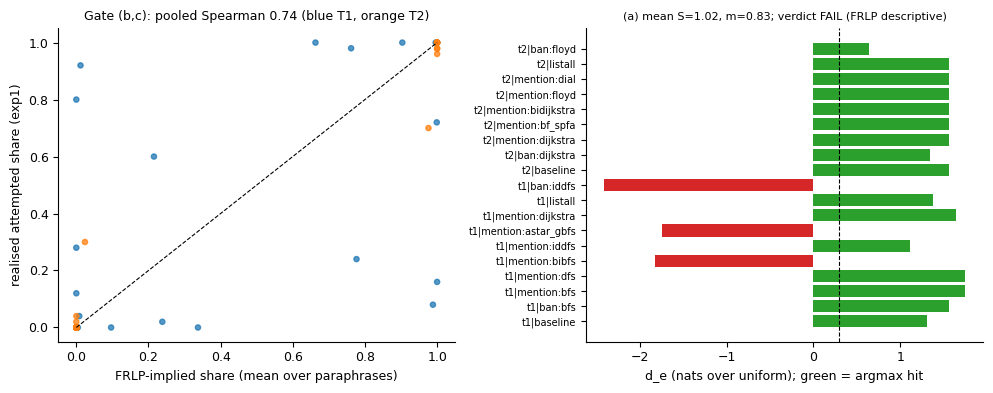

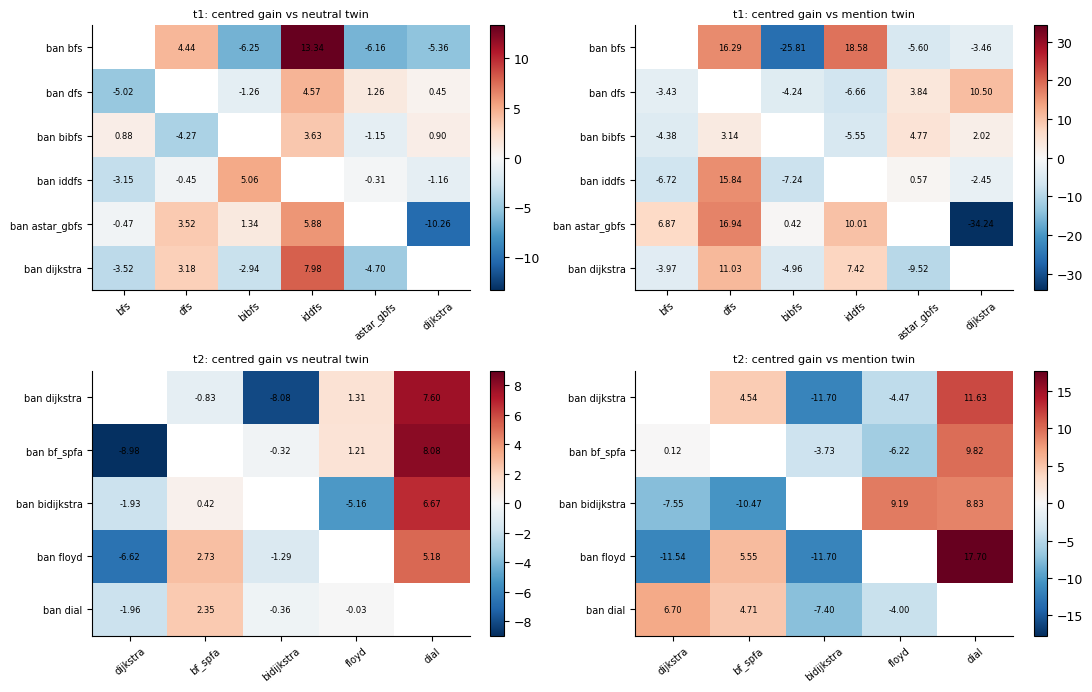

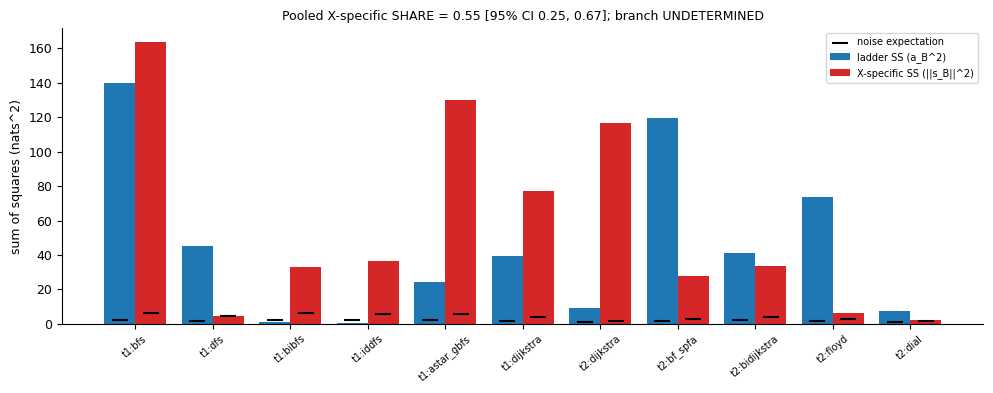

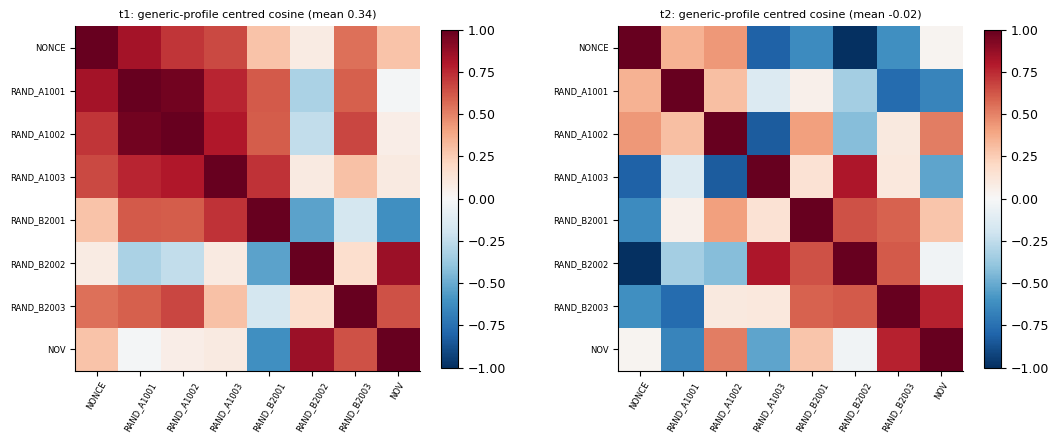

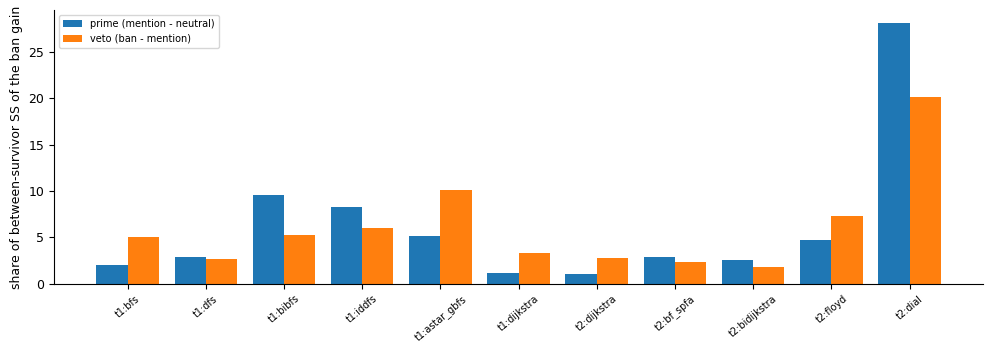

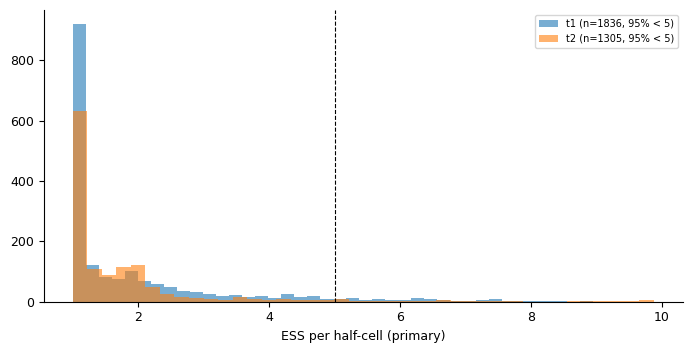

11:40:31|INFO   |method_out.json: [('frlp_gate_events', 19), ('c1_rows', 11)]


In [21]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})


def _load(name: str) -> Any:
    p = RESULTS / name
    return read_json(p) if p.exists() else None


def js(o: Any) -> str:
    return json.dumps(o, sort_keys=True, default=lambda x: None if isinstance(x, float) and math.isnan(x) else x)


def clean(o: Any) -> Any:
    if isinstance(o, float):
        return None if (math.isnan(o) or math.isinf(o)) else o
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating,)):
        return clean(float(o))
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


def build_method_out() -> dict[str, Any]:
    gate = _load("gate.json")
    c1 = _load("c1.json")
    events = read_json(RESULTS / "gate_events.json")
    ex_gate = []
    gmap = {e["event_id"]: e for e in (gate["primary"]["events"] if gate else [])}
    for e in events["events"]:
        g = gmap.get(e["event_id"])
        allowed = [j for j in MODES[e["task"]] if j not in e["banned"]]
        uni = {j: 0.98 / len(allowed) for j in allowed}
        uni["other"] = 0.02
        n_al = sum(e["distribution_allowed"].values()) or 1
        ex_gate.append({
            "input": f"[{e['event_id']}] exp1 prompt (paraphrase {e['paraphrases'][0]['paraphrase_id']}):\n"
                     + e["paraphrases"][0]["prompt"],
            "output": js({k: v / n_al for k, v in e["distribution_allowed"].items()}),
            "predict_frlp": js(g["implied_mean"]) if g else "null",
            "predict_uniform": js(uni),
            "metadata_task": e["task"], "metadata_condition": e["condition"], "metadata_banned": e["banned"],
            "metadata_n_samples": e["n_samples"], "metadata_realised_mode": e["realised_mode"],
            "metadata_clear_mode": e["clear_mode"], "metadata_d_e_nats": clean(g["d_e"]) if g else None,
            "metadata_argmax_hit": g["hit"] if g else None,
            "metadata_paraphrase_d": clean([p["d"] for p in g["paraphrases"]]) if g else None,
            "metadata_cell_ess": clean([p["ess"] for p in g["paraphrases"]]) if g else None,
        })
    ex_rows = []
    if c1:
        P = c1["primary_neutral"]
        R2 = c1["reference_mention"]
        assoc = read_json(RESULTS / "association.json")["profiles"]
        for t in TASKS:
            for B, r in P["tasks"][t]["rows"].items():
                r2 = R2["tasks"][t]["rows"].get(B, {})
                pv = {j: (r["pv_h1"][j] + r["pv_h2"][j]) / 2 for j in r["survivors"]}
                ex_rows.append({
                    "input": f"[{t}|ban:{B}] centred FRLP gain profile Gbar_B over survivors {r['survivors']} "
                             f"(ban vs token-matched neutral twin, 5 templates x 2 program halves)",
                    "output": js(clean(r["Gbar"])),
                    "predict_ladder": js(clean(r["fitted_ladder"])),
                    "predict_prime_and_veto": js(clean(pv)),
                    "predict_association": js(clean({j: assoc.get(f"{t}|{B}", {}).get(j) for j in r["survivors"]})),
                    "metadata_task": t, "metadata_ban": B, "metadata_a_ladder": clean(r["a"]),
                    "metadata_ss_ladder": clean(r["a2"]), "metadata_ss_specific": clean(r["ss_s"]),
                    "metadata_noise_N_u": clean(r["N_u"]), "metadata_noise_N_s": clean(r["N_s"]),
                    "metadata_x_specific_residual": clean(r["s"]), "metadata_rho_prime_veto": clean(r["rho_pv"]),
                    "metadata_rho_association": clean(r["rho_assoc"]),
                    "metadata_cos_with_ladder": clean(r["cos_with_u"]),
                    "metadata_n_low_ess_cells": r["n_flagged_cells"],
                    "metadata_Gbar_mention_reference": clean(r2.get("Gbar")),
                })
    meta = {
        "method_name": "FRLP output-space share test (substitute vs ladder)",
        "description": "Forced-ratio latent probabilities (mixture-proposal importance sampling over forced programs, "
                       "yield-corrected) scored by teacher forcing on Qwen3-8B; single-ban gain profiles decomposed "
                       "into a generic ladder share (external profile from nonce bans, matched-norm random prompt-band "
                       "edits and a novelty instruction) and an X-specific residual, with an aim test against the "
                       "prime-and-veto and free-form association profiles.",
        "model": MODEL_ID, "model_revision": MODEL_REV, "utc": utc_now(),
        "labeller_recheck": _load("labeller_recheck.json"), "yields": _load("yields.json"),
        "gate": gate, "c1": c1, "sensitivity": _load("sensitivity.json"), "secondary": _load("secondary.json"),
        "coverage": _load("coverage.json"), "ess": _load("ess_table.json"), "association": _load("association.json"),
        "synthetic_c1_test": _load("synthetic_c1_test.json"),
        "scorer_validation": read_json(LOGS / "scorer_validation.json") if (LOGS / "scorer_validation.json").exists() else None,
        "throughput": read_json(LOGS / "throughput.json") if (LOGS / "throughput.json").exists() else None,
        "queue": read_json(LOGS / "queue_final.json") if (LOGS / "queue_final.json").exists() else None,
        "timings": _load("timings.json"), "openrouter_cost": _load("openrouter_cost.json"),
        "deviations": _load("deviations.json"), "protocol": _load("protocol.json"),
        "mixture_identity": _load("mixture_identity.json"), "rederivation": _load("independent_rederivation.json"),
    }
    out = {"metadata": clean(meta), "datasets": [{"dataset": "frlp_gate_events", "examples": ex_gate}]}
    if ex_rows:
        out["datasets"].append({"dataset": "c1_rows", "examples": ex_rows})
    return out


# ------------------------------------------------------------------------------------------------ figures
def fig_gate(gate: dict[str, Any]) -> None:
    ev = gate["primary"]["events"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    xs, ys, cs = [], [], []
    for e in ev:
        n = sum(v for v in e["realised_allowed"].values()) or 1
        for j, q in e["implied_mean"].items():
            xs.append(q)
            ys.append(e["realised_allowed"].get(j, 0) / n)
            cs.append("tab:blue" if e["event_id"].startswith("t1") else "tab:orange")
    axes[0].scatter(xs, ys, c=cs, s=14, alpha=0.75)
    axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[0].set_xlabel("FRLP-implied share (mean over paraphrases)")
    axes[0].set_ylabel("realised attempted share (exp1)")
    axes[0].set_title(f"Gate (b,c): pooled Spearman {gate['primary']['pooled_spearman_implied_vs_realised']:.2f} "
                      "(blue T1, orange T2)", fontsize=9)
    names = [e["event_id"] for e in ev]
    d = [e["d_e"] for e in ev]
    axes[1].barh(range(len(names)), d, color=["tab:green" if e["hit"] else "tab:red" for e in ev])
    axes[1].axvline(0.3, color="k", ls="--", lw=0.8)
    axes[1].set_yticks(range(len(names)))
    axes[1].set_yticklabels(names, fontsize=7)
    axes[1].set_xlabel("d_e (nats over uniform); green = argmax hit")
    a = gate["primary"]["a"]
    axes[1].set_title(f"(a) mean S={a['mean_S']:.2f}, m={a['mean_m_default']:.2f}; verdict {gate['verdict']}",
                      fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGS / "F1_gate.png", dpi=160)
    fig.savefig(FIGS / "F1_gate.pdf")
    plt.show()   # DEMO: original plt.close(fig)


def fig_heatmaps(c1: dict[str, Any]) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for ci, key in enumerate(("primary_neutral", "reference_mention")):
        for ti, t in enumerate(TASKS):
            ax = axes[ti, ci]
            rows = c1[key]["tasks"][t]["rows"]
            js_ = c1[key]["tasks"][t]["measurable"]
            M = np.full((len(MODES[t]), len(js_)), np.nan)
            for bi, B in enumerate(MODES[t]):
                if B in rows:
                    for j, v in rows[B]["Gbar"].items():
                        M[bi, js_.index(j)] = v
            lim = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1
            im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
            ax.set_xticks(range(len(js_)))
            ax.set_xticklabels(js_, rotation=40, fontsize=7)
            ax.set_yticks(range(len(MODES[t])))
            ax.set_yticklabels([f"ban {b}" for b in MODES[t]], fontsize=7)
            for (i, k), v in np.ndenumerate(M):
                if np.isfinite(v):
                    ax.text(k, i, f"{v:.2f}", ha="center", va="center", fontsize=6)
            ax.set_title(f"{t}: centred gain vs {'neutral' if ci == 0 else 'mention'} twin", fontsize=8)
            fig.colorbar(im, ax=ax, fraction=0.04)
    fig.tight_layout()
    fig.savefig(FIGS / "F2_gain_heatmaps.png", dpi=160)
    fig.savefig(FIGS / "F2_gain_heatmaps.pdf")
    plt.show()   # DEMO: original plt.close(fig)


def fig_share(c1: dict[str, Any]) -> None:
    P = c1["primary_neutral"]
    labels, lad, spec, nu, ns = [], [], [], [], []
    for t in TASKS:
        for B, r in P["tasks"][t]["rows"].items():
            labels.append(f"{t}:{B}")
            lad.append(r["a2"])
            spec.append(r["ss_s"])
            nu.append(r["N_u"])
            ns.append(r["N_s"])
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - 0.2, lad, 0.4, label="ladder SS (a_B^2)", color="tab:blue")
    ax.bar(x + 0.2, spec, 0.4, label="X-specific SS (||s_B||^2)", color="tab:red")
    ax.scatter(x - 0.2, nu, marker="_", color="k", s=120, label="noise expectation")
    ax.scatter(x + 0.2, ns, marker="_", color="k", s=120)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=40, fontsize=7)
    pb = P["pooled"].get("bootstrap", {})
    sp = P["pooled"]["share_point"]
    ci = pb.get("SHARE_ci", [math.nan, math.nan])
    ax.set_title(f"Pooled X-specific SHARE = {sp['SHARE']:.2f} [95% CI {ci[0]:.2f}, {ci[1]:.2f}]; "
                 f"branch {P['pooled'].get('branch')}", fontsize=9)
    ax.set_ylabel("sum of squares (nats^2)")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(FIGS / "F3_share.png", dpi=160)
    fig.savefig(FIGS / "F3_share.pdf")
    plt.show()   # DEMO: original plt.close(fig)


def fig_cos(c1: dict[str, Any]) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, t in zip(axes, TASKS):
        le = c1["primary_neutral"]["tasks"][t].get("ladder_exists", {})
        mat = le.get("matrix", {})
        names = list(mat)
        M = np.array([[mat[a][b] for b in names] for a in names]) if names else np.zeros((1, 1))
        im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(len(names)))
        ax.set_xticklabels(names, rotation=60, fontsize=6)
        ax.set_yticks(range(len(names)))
        ax.set_yticklabels(names, fontsize=6)
        ax.set_title(f"{t}: generic-profile centred cosine (mean {le.get('mean_pairwise_centred_cosine', math.nan):.2f})",
                     fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.04)
    fig.tight_layout()
    fig.savefig(FIGS / "F4_generic_cosines.png", dpi=160)
    fig.savefig(FIGS / "F4_generic_cosines.pdf")
    plt.show()   # DEMO: original plt.close(fig)


def fig_prime_veto(c1: dict[str, Any]) -> None:
    P = c1["primary_neutral"]
    labels, pr, ve = [], [], []
    for t in TASKS:
        for B, x in P["tasks"][t].get("extras", {}).items():
            labels.append(f"{t}:{B}")
            pr.append(x["prime_share_of_ss"])
            ve.append(x["veto_share_of_ss"])
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.bar(x - 0.2, pr, 0.4, label="prime (mention - neutral)")
    ax.bar(x + 0.2, ve, 0.4, label="veto (ban - mention)")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=40, fontsize=7)
    ax.set_ylabel("share of between-survivor SS of the ban gain")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(FIGS / "F5_prime_veto.png", dpi=160)
    fig.savefig(FIGS / "F5_prime_veto.pdf")
    plt.show()   # DEMO: original plt.close(fig)


def fig_ess() -> None:
    rows = read_jsonl(RESULTS / "frlp_cells.jsonl")
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for t, c in (("t1", "tab:blue"), ("t2", "tab:orange")):
        e = [r["ess"] for r in rows if r["task"] == t and r["variant"] == "primary" and r["half"] != "all"
             and r["ess"] is not None]
        if e:
            ax.hist(e, bins=40, alpha=0.6, label=f"{t} (n={len(e)}, {np.mean(np.array(e) < 5):.0%} < 5)", color=c)
    ax.axvline(5, color="k", ls="--", lw=0.8)
    ax.set_xlabel("ESS per half-cell (primary)")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(FIGS / "F6_ess.png", dpi=160)
    fig.savefig(FIGS / "F6_ess.pdf")
    plt.show()   # DEMO: original plt.close(fig)


@logger.catch(reraise=True)
def main() -> None:
    setup_logging("outputs")
    gate = _load("gate.json")
    c1 = _load("c1.json")
    for fn, arg in ((fig_gate, gate), (fig_heatmaps, c1), (fig_share, c1), (fig_cos, c1), (fig_prime_veto, c1)):
        if arg is not None:
            try:
                fn(arg)
            except (KeyError, ValueError, TypeError) as e:
                logger.error(f"figure {fn.__name__} failed: {e}")
    try:
        fig_ess()
    except (KeyError, ValueError, TypeError) as e:
        logger.error(f"figure ess failed: {e}")
    out = build_method_out()
    write_json(ROOT / "method_out.json", out)
    logger.info(f"method_out.json: {[ (d['dataset'], len(d['examples'])) for d in out['datasets']]}")


main()   # == `uv run method.py outputs`

## Results: recomputed vs reported

The last cell puts the numbers recomputed in this notebook next to the values the artifact reported (stored in `metadata.reported`). There are two kinds of number:
- **Deterministic point estimates** (gate statistics, SHARE points, AIM values, ladder cosines, sensitivity points, two-step mass) must agree to floating-point precision whatever the configuration.
- **Resampling-dependent numbers** (bootstrap CIs, null quantiles, p-values, and the branch labels that use them) agree exactly at the original counts, which are the default: the bootstrap and permutation seeds are frozen in `src/config.py` and `c1.py`. With smaller counts they are approximate.

The forest plot shows the C1 SHARE with its bootstrap CI for every reference and scope, next to the reported CI. The dashed line at 0.5 is the decision threshold:
- CI entirely above 0.5: X-specific
- CI entirely below 0.5, with a coherent ladder: LADDER
- otherwise: UNDETERMINED

**What the numbers say.**
- FRLP fails its calibration check on name-scrubbed programs, so every C1 number is descriptive.
- Bans clearly *move* probability mass: $V_u + V_s$ is far above noise, so the effect is not pure subtraction.
- The pooled X-specific SHARE is about 0.55, and its CI straddles 0.5 under both references and the ESS weighting, so the pooled branch is UNDETERMINED.
- The residual is not aimed at the prime-and-veto profile or at the association profile.
- The generic perturbations do not agree with one another, so there is no single coherent ladder either.

Deterministic point estimates: 56 quantities, max |recomputed - reported| = 0.00e+00
Labels (verdicts / pass flags / branches): 16/16 agree


,group,quantity,recomputed,reported,abs diff,kind
6,gate,verdict,FAIL (FRLP descriptive),FAIL (FRLP descriptive),NaN,label
9,gate variants,code_body_only: passes all three,False,False,NaN,label
12,gate variants,correct_only: passes all three,False,False,NaN,label
15,gate variants,single_proposal: passes all three,True,True,NaN,label
18,gate variants,truncated_256: passes all three,False,False,NaN,label
21,gate variants,unscrubbed: passes all three,True,True,NaN,label
24,gate variants,unscrubbed_body_single: passes all three,True,True,NaN,label
27,C1 primary_neutral,t1: SHARE CI low,0.278876,0.278876,0.0,bootstrap: 2000 vs 2000 reps
28,C1 primary_neutral,t1: SHARE CI high,0.827273,0.827273,0.0,bootstrap: 2000 vs 2000 reps
29,C1 primary_neutral,t1: branch,UNDETERMINED,UNDETERMINED,NaN,label (uses the CIs)


,group,quantity,recomputed,reported,abs diff,kind
0,gate,(a) mean S,1.015041,1.015041,0.0,point
1,gate,(a) mean default-mode share m,0.829794,0.829794,0.0,point
2,gate,(b) mean d_e (nats),0.919244,0.919244,0.0,point
3,gate,(c) argmax hits (of 19),16,16,0.0,point
4,gate,pooled Spearman implied vs realised,0.738509,0.738509,0.0,point
5,gate,gate cells with ESS < 5,298,298,0.0,point
7,gate variants,code_body_only: mean m,0.829794,0.829794,0.0,point
8,gate variants,code_body_only: mean d_e,0.919244,0.919244,0.0,point
10,gate variants,correct_only: mean m,0.9999,0.9999,0.0,point
11,gate variants,correct_only: mean d_e,0.758953,0.758953,0.0,point


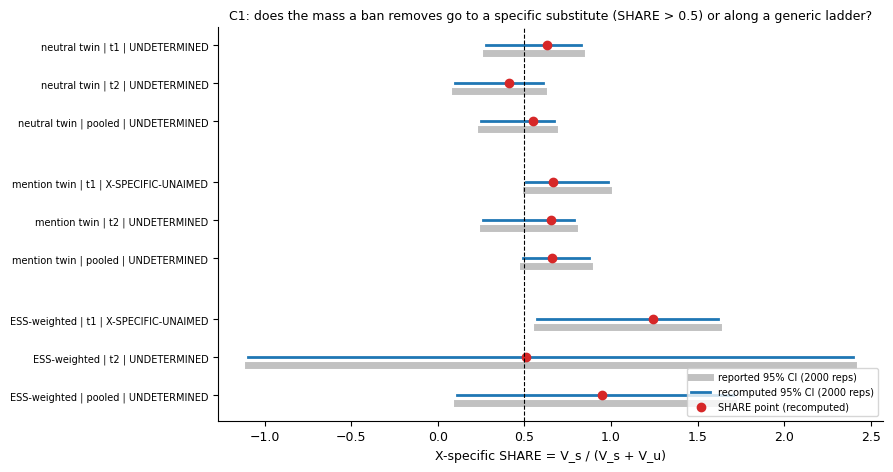

Notebook runtime after the install cell: 69 s


In [22]:
rep = md["reported"]
G, C, SENS, SEC = (read_json(RESULTS / f) for f in ("gate.json", "c1.json", "sensitivity.json", "secondary.json"))
cmp_rows = []


def add(group, name, new, old, kind="point"):
    num = all(isinstance(v, (int, float)) and not isinstance(v, bool) for v in (new, old))
    cmp_rows.append({"group": group, "quantity": name, "recomputed": new, "reported": old,
                     "abs diff": abs(new - old) if num else None, "kind": kind})


boot = f"bootstrap: {DEMO_N_BOOT} vs 2000 reps"
perm = f"permutation: {DEMO_N_PERM:,} vs 200,000 draws"
gp, rp = G["primary"], rep["gate"]["primary"]
add("gate", "(a) mean S", gp["a"]["mean_S"], rp["a"]["mean_S"])
add("gate", "(a) mean default-mode share m", gp["a"]["mean_m_default"], rp["a"]["mean_m_default"])
add("gate", "(b) mean d_e (nats)", gp["b"]["mean_d_e"], rp["b"]["mean_d_e"])
add("gate", "(c) argmax hits (of 19)", gp["c"]["hits"], rp["c"]["hits"])
add("gate", "pooled Spearman implied vs realised", gp["pooled_spearman_implied_vs_realised"],
    rp["pooled_spearman_implied_vs_realised"])
add("gate", "gate cells with ESS < 5", gp["ess_cells"]["n_below_5"], rp["ess_cells"]["n_below_5"])
add("gate", "verdict", G["verdict"], rep["gate"]["verdict"], "label")
for v, s in G["sensitivity"].items():
    r = rep["gate"]["sensitivity"][v]
    add("gate variants", f"{v}: mean m", s["a"]["mean_m_default"], r["a"]["mean_m_default"])
    add("gate variants", f"{v}: mean d_e", s["b"]["mean_d_e"], r["b"]["mean_d_e"])
    add("gate variants", f"{v}: passes all three", s["pass"], r["pass"], "label")
for ref in ("primary_neutral", "reference_mention", "ess_weighted"):
    R, Rr = C[ref], rep["c1"][ref]
    for scope in ("t1", "t2", "pooled"):
        s = R["tasks"][scope] if scope != "pooled" else R["pooled"]
        add(f"C1 {ref}", f"{scope}: SHARE point", s["share_point"]["SHARE"], Rr[scope]["share_point"]["SHARE"])
        add(f"C1 {ref}", f"{scope}: V_u + V_s", s["share_point"]["V_tot"], Rr[scope]["share_point"]["V_tot"])
        add(f"C1 {ref}", f"{scope}: SHARE CI low", s["bootstrap"]["SHARE_ci"][0], Rr[scope]["SHARE_ci"][0], boot)
        add(f"C1 {ref}", f"{scope}: SHARE CI high", s["bootstrap"]["SHARE_ci"][1], Rr[scope]["SHARE_ci"][1], boot)
        add(f"C1 {ref}", f"{scope}: branch", s["branch"], Rr[scope]["branch"], "label (uses the CIs)")
    add(f"C1 {ref}", "AIM prime-and-veto", R["aim_prime_veto"]["aim"], Rr["aim_prime_veto"]["aim"])
    add(f"C1 {ref}", "AIM null 95th percentile", R["aim_prime_veto"]["null_p95"], Rr["aim_prime_veto"]["null_p95"], perm)
    add(f"C1 {ref}", "AIM p-value", R["aim_prime_veto"]["p"], Rr["aim_prime_veto"]["p"], perm)
add("C1 primary_neutral", "association aim", C["primary_neutral"]["aim_association"]["aim"],
    rep["c1"]["primary_neutral"]["aim_association"]["aim"])
for t in TASKS:
    add("C1 primary_neutral", f"{t}: ladder mean centred cosine",
        C["primary_neutral"]["tasks"][t]["ladder_exists"]["mean_pairwise_centred_cosine"],
        rep["c1"]["primary_neutral"][t]["ladder_mean_centred_cosine"])
for k, v in SENS.items():
    if "error" not in v:
        add("C1 sensitivity", f"{k}: pooled SHARE point", v["pooled_share_point"]["SHARE"],
            rep["sensitivity"][k]["pooled_share_point"])
for t in TASKS:
    add("secondary", f"{t}: two-step implied banned mass", SEC["two_step"][t]["implied_banned_mass_frozen_templates"],
        rep["secondary_two_step"][t]["implied_banned_mass_frozen_templates"])

cmp_df = pd.DataFrame(cmp_rows)
pts = cmp_df[cmp_df["kind"] == "point"]
lab = cmp_df[cmp_df["kind"].str.startswith("label")]
print(f"Deterministic point estimates: {len(pts)} quantities, max |recomputed - reported| = "
      f"{pts['abs diff'].max():.2e}")
print(f"Labels (verdicts / pass flags / branches): {int((lab['recomputed'] == lab['reported']).sum())}/{len(lab)} agree")
display(cmp_df[cmp_df["kind"] != "point"].round(3))
display(pts.round(4))

# Forest plot of the C1 SHARE (recomputed point + CI vs the reported CI)
fig, ax = plt.subplots(figsize=(9, 4.8))
y, yt, ylab = 0.0, [], []
for ref, name in (("primary_neutral", "neutral twin"), ("reference_mention", "mention twin"),
                  ("ess_weighted", "ESS-weighted")):
    for scope in ("t1", "t2", "pooled"):
        s = C[ref]["tasks"][scope] if scope != "pooled" else C[ref]["pooled"]
        r = rep["c1"][ref][scope]
        ax.plot(r["SHARE_ci"], [y - 0.2] * 2, color="0.6", lw=5, alpha=0.6,
                label="reported 95% CI (2000 reps)" if not yt else None)
        ax.plot(s["bootstrap"]["SHARE_ci"], [y, y], color="tab:blue", lw=2,
                label=f"recomputed 95% CI ({DEMO_N_BOOT} reps)" if not yt else None)
        ax.plot(s["share_point"]["SHARE"], y, "o", color="tab:red", label="SHARE point (recomputed)" if not yt else None)
        yt.append(y)
        ylab.append(f"{name} | {scope} | {s['branch']}")
        y -= 1
    y -= 0.6
ax.axvline(0.5, ls="--", color="k", lw=0.8)
ax.set_yticks(yt)
ax.set_yticklabels(ylab, fontsize=7)
ax.set_xlabel("X-specific SHARE = V_s / (V_s + V_u)")
ax.set_title("C1: does the mass a ban removes go to a specific substitute (SHARE > 0.5) or along a generic ladder?",
             fontsize=9)
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
plt.show()
print(f"Notebook runtime after the install cell: {time.time() - T_START:.0f} s")